# Prédire la cause d'un feu de forêt dès sa découverte — Étape 2 (Spark)

## 0. Introduction

**Problème.** Prédire la **cause** d'un feu de forêt (foudre, incendie criminel, brûlage de débris, feu de camp, équipement…) à partir des seules informations disponibles **au moment de sa découverte** : lieu, date et heure de découverte, type de propriétaire du terrain, organisme qui signale le feu. C'est une classification **multiclasse**.

**Cas d'usage.**
1. Orienter les enquêteurs dès la découverte (quelles pistes vérifier en premier).
2. Estimer la cause des feux dont la cause n'a jamais été déterminée.

**Données.** *Fire Program Analysis Fire-Occurrence Database* (FPA FOD), US Forest Service. Le fichier fourni (`archive.zip`) contient **`FPA_FOD_20170508.sqlite`**, c'est-à-dire la **4e édition (1992-2015)**, et non la 6e édition (FPA_FOD_20221014, 1992-2020) prévue dans le cahier des charges. Le notebook est adapté à cette édition : noms de colonnes de l'ancienne version (`STAT_CAUSE_DESCR`), date de découverte en jour julien, découpage temporel jusqu'en 2015.

> Short, Karen C. 2017. *Spatial wildfire occurrence data for the United States, 1992-2015 [FPA_FOD_20170508]*. 4th Edition. Fort Collins, CO: Forest Service Research Data Archive. https://doi.org/10.2737/RDS-2013-0009.4

**Lien avec l'étape 1.** Même workflow que pour les attaques de requins (pandas, scikit-learn), mais avec environ 1,9 million de lignes au lieu de 4 000 : ingestion dans un format adapté, agrégations distribuées, pipeline `pyspark.ml`, et comparaison chiffrée scikit-learn / Spark (section 9).

| Étape | Contenu |
|---|---|
| 1. Ingestion | SQLite → Parquet, une seule fois |
| 2. Données et cadrage | schéma, valeurs manquantes, cible |
| 3. Fuites | classement des colonnes, mesures |
| 4. EDA | agrégations Spark, graphiques sur agrégats ou échantillons |
| 5. Prétraitement | `src/preparation.py` en SQL Spark natif, testé |
| 6. Découpage et pipeline | découpage temporel, `pyspark.ml.Pipeline`, poids de classes |
| 7. Modélisation | 2 références, régression logistique, random forest, réglage |
| 8. Évaluation finale | test unique, confusions, importances, fuite, causes inconnues |
| 9. Passage à l'échelle | scikit-learn contre Spark selon le volume |
| 10. Déploiement (préparation) | `PipelineModel`, schéma, prédiction d'exemple |
| 11. Conclusion | |

In [1]:
# Configuration de l'environnement AVANT la création de la SparkSession
import json
import os
import shutil
import sqlite3
import subprocess
import sys
import time
from pathlib import Path

os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-11-openjdk-amd64"
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"            # évite l'avertissement d'adresse de bouclage sous WSL
for var in ("HADOOP_CONF_DIR", "YARN_CONF_DIR"):      # sinon Spark chercherait les fichiers dans HDFS (arrêté)
    os.environ.pop(var, None)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psutil
import seaborn as sns
from pyspark.sql import SparkSession, functions as F

RACINE = Path.cwd()                                   # le notebook est à la racine du projet
assert (RACINE / "data").is_dir(), "Lancer le notebook depuis la racine du projet"
sys.path.insert(0, str(RACINE))
SEED = 42
DEBUT_NOTEBOOK = time.time()

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

**Écarts avec le cahier des charges** (adaptations à ce qui a été observé) :

| Prévu | Réalisé | Raison |
|---|---|---|
| 6e édition (1992-2020, `NWCG_GENERAL_CAUSE`) | **4e édition (1992-2015, `STAT_CAUSE_DESCR`)** | c'est le fichier fourni dans `archive.zip` |
| Découpage 1992-2014 / 2015-2017 / 2018-2020 | **1992-2009 / 2010-2012 / 2013-2015** | données jusqu'en 2015 |
| `TrainValidationSplit` | grille parcourue à la main sur la validation temporelle | `TrainValidationSplit` découpe aléatoirement (section 7.2) |
| Forêt jusqu'à la profondeur 15 | profondeur ≤ 12 | `OutOfMemoryError` mesuré en prédiction avec 4 Go (section 7.2) |
| Copie dans HDFS (facultatif) | non réalisée | non nécessaire ; le notebook ne dépend pas de HDFS |
| Paquet `pyarrow` | installé dans le venv | nécessaire pour écrire le Parquet depuis pandas |

In [2]:
spark = (SparkSession.builder
         .master("local[*]")
         .appName("etape2_feux")
         .config("spark.driver.memory", "4g")               # 8,2 Go pour WSL : on en laisse pour Python et l'OS
         .config("spark.sql.shuffle.partitions", "24")      # 2 x 12 threads au lieu de 200 par défaut
         .config("spark.memory.fraction", "0.5")            # plus de place pour les objets modèles (forêts) ;
                                                            # les caches débordent sur disque si besoin
         .config("spark.ui.showConsoleProgress", "false")
         .config("spark.sql.session.timeZone", "UTC")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

java = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr.splitlines()[0]
print("Spark          :", spark.version)
print("Java           :", java)
print("Python         :", sys.version.split()[0])
print("Mode           :", spark.sparkContext.master, "| parallélisme par défaut :", spark.sparkContext.defaultParallelism)
print("Threads (OS)   :", os.cpu_count())
print(f"Mémoire WSL    : {psutil.virtual_memory().total / 1e9:.1f} Go | mémoire du driver Spark :",
      spark.conf.get("spark.driver.memory"))
print("Partitions de shuffle :", spark.conf.get("spark.sql.shuffle.partitions"))


def liberer_memoire():
    """Libère les objets Python devenus inutiles (et leurs références vers la JVM), puis demande un GC Java."""
    import gc
    gc.collect()
    spark.sparkContext._jvm.System.gc()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/11/13 13:00:08 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark          : 3.5.9
Java           : openjdk version "11.0.32.1" 2026-08-18
Python         : 3.10.12
Mode           : local[*] | parallélisme par défaut : 12
Threads (OS)   : 12


Mémoire WSL    : 8.2 Go | mémoire du driver Spark : 4g
Partitions de shuffle : 24


La session tourne en `local[*]` sur les 12 threads, avec 4 Go pour le driver (qui est aussi l'exécuteur en mode local). Les messages en rouge ne sont **pas des erreurs**, et ils ne sont pas masqués :
- `Setting default log level to "WARN"` : simple information de Spark au démarrage ;
- `NativeCodeLoader: Unable to load native-hadoop library` : les bibliothèques natives Hadoop (C) ne sont pas installées pour ce Spark, qui utilise donc leurs équivalents Java. Le résultat est identique.

`spark.memory.fraction=0.5` laisse davantage de mémoire aux objets des modèles (une forêt occupe des centaines de Mo) ; les données en cache débordent sur disque si nécessaire. Ce réglage a été adopté après des `OutOfMemoryError` lors des premiers essais.

## 1. Ingestion des données

### 1.1 Inspection de la base SQLite

In [3]:
CHEMIN_SQLITE = RACINE / "data" / "FPA_FOD_20170508.sqlite"
con = sqlite3.connect(f"file:{CHEMIN_SQLITE}?mode=ro", uri=True)       # lecture seule
tables = pd.read_sql("SELECT name, type FROM sqlite_master WHERE type = 'table' AND name NOT LIKE 'sqlite_%' "
                     "AND name NOT LIKE 'idx_%' AND name NOT LIKE '%geometry%' AND name NOT LIKE 'spatial%' "
                     "ORDER BY name", con)
print(tables.to_string(index=False))
print("\nLignes de la table Fires :", pd.read_sql("SELECT COUNT(*) AS n FROM Fires", con)["n"][0])
colonnes_sqlite = pd.read_sql("PRAGMA table_info(Fires)", con)[["name", "type"]]
print(colonnes_sqlite.to_string(index=False))

                      name  type
      ElementaryGeometries table
                     Fires table
                       KNN table
NWCG_UnitIDActive_20170109 table
        sql_statements_log table



Lignes de la table Fires : 1880465
                      name      type
                  OBJECTID   INTEGER
                    FOD_ID     int32
                    FPA_ID text(100)
        SOURCE_SYSTEM_TYPE text(255)
             SOURCE_SYSTEM  text(30)
     NWCG_REPORTING_AGENCY text(255)
    NWCG_REPORTING_UNIT_ID text(255)
  NWCG_REPORTING_UNIT_NAME text(255)
     SOURCE_REPORTING_UNIT  text(30)
SOURCE_REPORTING_UNIT_NAME text(255)
      LOCAL_FIRE_REPORT_ID text(255)
         LOCAL_INCIDENT_ID text(255)
                 FIRE_CODE  text(10)
                 FIRE_NAME text(255)
   ICS_209_INCIDENT_NUMBER text(255)
              ICS_209_NAME text(255)
                   MTBS_ID text(255)
            MTBS_FIRE_NAME  text(50)
              COMPLEX_NAME text(255)
                 FIRE_YEAR     int16
            DISCOVERY_DATE  realdate
             DISCOVERY_DOY     int32
            DISCOVERY_TIME   text(4)
           STAT_CAUSE_CODE   float64
          STAT_CAUSE_DESCR text(100)
  

La base contient une seule table utile, **`Fires` (1 880 465 lignes, 38 colonnes + la géométrie `Shape`)**. Les autres tables sont des métadonnées SpatiaLite (index spatiaux, systèmes de coordonnées) et un référentiel des unités (`NWCG_UnitIDActive_20170109`), dont on n'a pas besoin : l'identifiant d'unité figure déjà dans `Fires`.

### 1.2 Conversion en Parquet (une seule fois)

**Choix : lecture pandas par blocs plutôt que JDBC.**
- Spark ne lit pas SQLite nativement, et le pilote JDBC SQLite (`sqlite-jdbc`) n'est pas installé dans cet environnement. Il faudrait le télécharger et l'ajouter au classpath, et la lecture JDBC d'une base SQLite reste mono-fichier et difficile à paralléliser.
- `pandas.read_sql(..., chunksize=200_000)` lit la table par blocs : la mémoire Python reste bornée (un bloc à la fois), et chaque bloc est écrit directement en un fichier Parquet par `pyarrow`.
- On ignore la géométrie binaire `Shape` (redondante avec `LATITUDE`/`LONGITUDE`) et l'on fixe un **schéma explicite**. Sinon un bloc dont une colonne texte est entièrement vide recevrait un type différent, et les fichiers seraient incompatibles entre eux.

**Pourquoi Parquet pour Spark.**
- **Format en colonnes** : une requête qui n'utilise que 5 colonnes ne lit que ces 5 colonnes sur le disque (*projection pushdown*).
- **Compression** par colonne (Snappy), très efficace sur des valeurs répétitives (codes d'État, causes).
- **Statistiques par bloc** (min/max) qui permettent de sauter des blocs entiers lors d'un filtre (*predicate pushdown*).
- Fichiers multiples lus **en parallèle** par les 12 threads ; schéma typé stocké dans le fichier.

In [4]:
import pyarrow as pa
import pyarrow.parquet as pq
from src import preparation as prep

CHEMIN_PARQUET = RACINE / "data" / "fires.parquet"
CHEMIN_INGESTION = RACINE / "results" / "ingestion.json"
TYPES_SQLITE = dict(zip(colonnes_sqlite["name"], colonnes_sqlite["type"].str.lower()))


def type_arrow(t: str):
    if t.startswith("int"):
        return pa.int64()
    if t.startswith("float") or t.startswith("real") or t == "realdate":
        return pa.float64()
    return pa.string()


SCHEMA_ARROW = pa.schema([(c, type_arrow(TYPES_SQLITE[c])) for c in prep.COLONNES_SOURCE])


def convertir_sqlite_en_parquet(taille_bloc: int = 200_000) -> dict:
    """Lit la table Fires par blocs et écrit un dossier Parquet (un fichier par bloc).
    Écriture dans un dossier temporaire renommé à la fin : un échec ne laisse pas de Parquet partiel."""
    tmp = CHEMIN_PARQUET.with_suffix(".tmp")
    shutil.rmtree(tmp, ignore_errors=True)
    tmp.mkdir(parents=True)
    t0, n = time.time(), 0
    requete = "SELECT " + ", ".join(prep.COLONNES_SOURCE) + " FROM Fires"
    for i, bloc in enumerate(pd.read_sql(requete, con, chunksize=taille_bloc)):
        table = pa.Table.from_pandas(bloc, schema=SCHEMA_ARROW, preserve_index=False)
        pq.write_table(table, tmp / f"part-{i:04d}.parquet", compression="snappy")
        n += len(bloc)
    tmp.rename(CHEMIN_PARQUET)
    return {"lignes": n, "duree_s": round(time.time() - t0, 1), "taille_bloc": taille_bloc}


if CHEMIN_PARQUET.exists():
    print("Parquet déjà présent : conversion non relancée.")
    ingestion = json.loads(CHEMIN_INGESTION.read_text())
else:
    ingestion = convertir_sqlite_en_parquet()
    taille_parquet = sum(f.stat().st_size for f in CHEMIN_PARQUET.glob("*.parquet"))
    ingestion.update({"taille_sqlite_Mo": round(CHEMIN_SQLITE.stat().st_size / 1e6, 1),
                      "taille_parquet_Mo": round(taille_parquet / 1e6, 1)})
    CHEMIN_INGESTION.parent.mkdir(exist_ok=True)
    CHEMIN_INGESTION.write_text(json.dumps(ingestion, indent=2))
con.close()
print(json.dumps(ingestion, indent=2))
print(f"Rapport de taille SQLite / Parquet : {ingestion['taille_sqlite_Mo'] / ingestion['taille_parquet_Mo']:.1f}")

Parquet déjà présent : conversion non relancée.
{
  "lignes": 1880465,
  "duree_s": 25.4,
  "taille_bloc": 200000,
  "taille_sqlite_Mo": 795.8,
  "taille_parquet_Mo": 90.7
}
Rapport de taille SQLite / Parquet : 8.8


La conversion a été faite **une seule fois** (lors de la première exécution) : **25,4 s** pour 1 880 465 lignes, par blocs de 200 000. Le Parquet pèse **90,7 Mo contre 795,8 Mo** pour le SQLite, soit **8,8 fois moins**, grâce à la compression par colonne et à l'absence d'index spatiaux. Aux exécutions suivantes, le dossier existe et la conversion est sautée (les mesures sont relues dans `results/ingestion.json`).

In [5]:
# Lecture Spark et démonstration de la lecture sélective des colonnes
df_brut = spark.read.parquet(str(CHEMIN_PARQUET))
print("Fichiers Parquet :", len(list(CHEMIN_PARQUET.glob("*.parquet"))), "| partitions Spark :", df_brut.rdd.getNumPartitions())

t0 = time.time(); n = df_brut.count(); t_count = time.time() - t0
t0 = time.time(); df_brut.agg(F.count("STAT_CAUSE_DESCR")).collect(); t_1col = time.time() - t0
t0 = time.time(); df_brut.agg(*[F.count(c) for c in df_brut.columns]).collect(); t_all = time.time() - t0
print(f"Lignes : {n} (comptage en {t_count:.1f} s)")
print(f"Comptage des non-nuls sur 1 colonne : {t_1col:.1f} s | sur les {len(df_brut.columns)} colonnes : {t_all:.1f} s")
plan = df_brut.select("STAT_CAUSE_DESCR", "STATE")._jdf.queryExecution().executedPlan().toString()
print("Colonnes réellement lues (plan physique) :", plan[plan.find("ReadSchema"):].split("\n")[0])

Fichiers Parquet : 10 | partitions Spark : 11


Lignes : 1880465 (comptage en 3.9 s)
Comptage des non-nuls sur 1 colonne : 2.5 s | sur les 38 colonnes : 12.4 s
Colonnes réellement lues (plan physique) : ReadSchema: struct<STAT_CAUSE_DESCR:string,STATE:string>


- Compter les 1,88 M lignes prend **3,9 s** : Parquet stocke le nombre de lignes dans ses métadonnées.
- Lire 1 colonne prend **2,5 s**, contre **12,4 s** pour les 38 (**5 fois plus**) : c'est la lecture sélective des colonnes.
- Le plan physique le confirme : pour `select("STAT_CAUSE_DESCR", "STATE")`, Spark ne lit que ces deux colonnes (`ReadSchema`).

## 2. Données et cadrage

### 2.1 Schéma, valeurs manquantes, cardinalités

In [6]:
df_brut.printSchema()

root
 |-- OBJECTID: long (nullable = true)
 |-- FOD_ID: long (nullable = true)
 |-- FPA_ID: string (nullable = true)
 |-- SOURCE_SYSTEM_TYPE: string (nullable = true)
 |-- SOURCE_SYSTEM: string (nullable = true)
 |-- NWCG_REPORTING_AGENCY: string (nullable = true)
 |-- NWCG_REPORTING_UNIT_ID: string (nullable = true)
 |-- NWCG_REPORTING_UNIT_NAME: string (nullable = true)
 |-- SOURCE_REPORTING_UNIT: string (nullable = true)
 |-- SOURCE_REPORTING_UNIT_NAME: string (nullable = true)
 |-- LOCAL_FIRE_REPORT_ID: string (nullable = true)
 |-- LOCAL_INCIDENT_ID: string (nullable = true)
 |-- FIRE_CODE: string (nullable = true)
 |-- FIRE_NAME: string (nullable = true)
 |-- ICS_209_INCIDENT_NUMBER: string (nullable = true)
 |-- ICS_209_NAME: string (nullable = true)
 |-- MTBS_ID: string (nullable = true)
 |-- MTBS_FIRE_NAME: string (nullable = true)
 |-- COMPLEX_NAME: string (nullable = true)
 |-- FIRE_YEAR: long (nullable = true)
 |-- DISCOVERY_DATE: double (nullable = true)
 |-- DISCOVERY_DOY

In [7]:
# Valeurs manquantes (NULL ou chaîne vide) et cardinalités approchées : UNE seule passe sur les données
exprs = []
for c, t in df_brut.dtypes:
    manquant = F.col(c).isNull() | (F.trim(F.col(c)) == "") if t == "string" else F.col(c).isNull()
    exprs += [F.sum(manquant.cast("int")).alias(f"{c}__nul"), F.approx_count_distinct(c, rsd=0.05).alias(f"{c}__card")]
t0 = time.time()
ligne = df_brut.agg(*exprs).collect()[0].asDict()
print(f"Passe unique : {time.time() - t0:.1f} s")
qualite = pd.DataFrame({
    "type": dict(df_brut.dtypes),
    "manquants_%": {c: round(100 * ligne[f"{c}__nul"] / n, 1) for c in df_brut.columns},
    "cardinalité (approx.)": {c: ligne[f"{c}__card"] for c in df_brut.columns},
})
qualite

Passe unique : 31.6 s


,type,manquants_%,cardinalité (approx.)
OBJECTID,bigint,0.0,1714103
FOD_ID,bigint,0.0,1764791
FPA_ID,string,0.0,1965259
SOURCE_SYSTEM_TYPE,string,0.0,3
SOURCE_SYSTEM,string,0.0,37
NWCG_REPORTING_AGENCY,string,0.0,11
NWCG_REPORTING_UNIT_ID,string,0.0,1676
NWCG_REPORTING_UNIT_NAME,string,0.0,1599
SOURCE_REPORTING_UNIT,string,0.0,4780
SOURCE_REPORTING_UNIT_NAME,string,0.0,4137


**Une seule passe Spark (31,6 s)** pour 38 colonnes × 2 indicateurs.
- **Aucun manque** sur la cause, la date de découverte, les coordonnées, l'État, le propriétaire et l'organisme : les variables principales sont complètes.
- **Heure de découverte : 46,9 % de manquants** ; maîtrise du feu (`CONT_*`) : 47 à 52 % ; nom du feu : 50,9 % ; comté (`COUNTY`, `FIPS_*`) : 36,1 %.
- Liens ICS-209 / MTBS : plus de 98 % de manquants. Ils n'existent que pour les grands feux.
- Les cardinalités sont **approchées** (HyperLogLog, erreur relative de l'ordre de 5 %), d'où 55 « États » au lieu de 52 exacts, ou 1,7 à 2,0 M pour des identifiants qui en comptent 1,88 M. Une valeur exacte demanderait un `countDistinct` par colonne, bien plus coûteux.

### 2.2 La cause des feux

In [8]:
causes_brutes = (df_brut.groupBy("STAT_CAUSE_CODE", "STAT_CAUSE_DESCR").count()
                 .orderBy(F.desc("count")).toPandas())
causes_brutes["part_%"] = (100 * causes_brutes["count"] / n).round(2)
causes_brutes

,STAT_CAUSE_CODE,STAT_CAUSE_DESCR,count,part_%
0,5.0,Debris Burning,429028,22.81
1,9.0,Miscellaneous,323805,17.22
2,7.0,Arson,281455,14.97
3,1.0,Lightning,278468,14.81
4,13.0,Missing/Undefined,166723,8.87
5,2.0,Equipment Use,147612,7.85
6,4.0,Campfire,76139,4.05
7,8.0,Children,61167,3.25
8,3.0,Smoking,52869,2.81
9,6.0,Railroad,33455,1.78


13 modalités ; le code numérique et le libellé se correspondent un à un. **166 723 feux (8,87 %) sont de cause « Missing/Undefined »**, et « Structure » est très rare (3 796 feux, 0,20 %).

In [9]:
# Cible : causes en français, « Structure » regroupée avec « Divers », « Missing/Undefined » mise à part
df_cause = prep.ajouter_cause(df_brut)
cibles = (df_cause.groupBy("cause").count().orderBy(F.desc("count")).toPandas()
          .assign(part_connues_pct=lambda d: (100 * d["count"] / d.loc[d["cause"].notna(), "count"].sum()).round(2)))
cibles.loc[cibles["cause"].isna(), "part_connues_pct"] = np.nan
cibles["cause"] = cibles["cause"].fillna("(inconnue : Missing/Undefined)")
cibles

,cause,count,part_connues_pct
0,Brûlage de débris,429028,25.03
1,Divers,327601,19.12
2,Incendie criminel,281455,16.42
3,Foudre,278468,16.25
4,(inconnue : Missing/Undefined),166723,NaN
5,Équipement,147612,8.61
6,Feu de camp,76139,4.44
7,Enfants,61167,3.57
8,Cigarette,52869,3.09
9,Chemin de fer,33455,1.95


**Définition de la cible.**
- 11 causes connues, soit 1 880 465 − 166 723 = **1 713 742 feux** pour l'apprentissage et l'évaluation.
- **Missing/Undefined** est exclue de l'apprentissage, mais conservée à part pour le cas d'usage (section 8.4).
- **Structure** (0,2 %) est regroupée avec **Divers**. C'est trop rare pour être appris (quelques centaines de feux par période de test), et ce libellé (« feu parti d'un bâtiment ») ne désigne pas une activité précise.
- **Feux d'artifice** (0,67 %) et **Ligne électrique** (0,84 %) sont rares mais **conservés** : la saison du 4 juillet et le réseau électrique leur donnent une signature propre.
- Déséquilibre : la classe la plus fréquente (25,0 %) est **37 fois** plus fréquente que la plus rare.

## 3. Fuites de données

### 3.1 Mesures

In [10]:
# a) Le code de cause est une simple traduction de la cause : couples (code, libellé) distincts
print("Couples (STAT_CAUSE_CODE, STAT_CAUSE_DESCR) distincts :",
      df_brut.select("STAT_CAUSE_CODE", "STAT_CAUSE_DESCR").distinct().count(), "pour 13 codes")

# b) Noms de feux contenant un mot de cause
MOTS_CAUSE = {"LIGHTNING": "Foudre", "ARSON": "Incendie criminel", "DEBRIS": "Brûlage de débris",
              "CAMPFIRE|CAMP FIRE": "Feu de camp", "RAILROAD|RR |TRAIN": "Chemin de fer",
              "POWERLINE|POWER LINE": "Ligne électrique", "FIREWORK": "Feux d'artifice",
              "SMOK|CIGARET": "Cigarette", "KIDS|CHILD": "Enfants", "EQUIPMENT|MOWER|TRACTOR": "Équipement"}
noms = df_cause.where(F.col("FIRE_NAME").isNotNull() & (F.trim("FIRE_NAME") != ""))
nom_maj = F.upper(F.col("FIRE_NAME"))
aggs = [F.count("*").alias("n_noms")]
for motif, cause in MOTS_CAUSE.items():
    m = nom_maj.rlike(motif)
    aggs += [F.sum(m.cast("int")).alias(f"{cause}__n"),
             F.sum((m & (F.col("cause") == cause)).cast("int")).alias(f"{cause}__ok")]
aggs.append(F.sum(nom_maj.rlike("|".join(MOTS_CAUSE)).cast("int")).alias("au_moins_un"))
r = noms.agg(*aggs).collect()[0].asDict()
print(f"Feux nommés : {r['n_noms']} ({r['n_noms'] / n:.1%} des feux) | nom contenant un mot de cause : "
      f"{r['au_moins_un']} ({r['au_moins_un'] / r['n_noms']:.2%} des feux nommés)")
pd.DataFrame([{"mot(s)": m, "cause associée": c, "feux": r[f"{c}__n"],
               "dont cause identique_%": round(100 * r[f"{c}__ok"] / r[f"{c}__n"], 1) if r[f"{c}__n"] else np.nan}
              for m, c in MOTS_CAUSE.items()]).sort_values("feux", ascending=False)

Couples (STAT_CAUSE_CODE, STAT_CAUSE_DESCR) distincts : 13 pour 13 codes


Feux nommés : 923276 (49.1% des feux) | nom contenant un mot de cause : 10927 (1.18% des feux nommés)


,mot(s),cause associée,feux,dont cause identique_%
4,RAILROAD|RR |TRAIN,Chemin de fer,2619,34.5
0,LIGHTNING,Foudre,2119,91.0
5,POWERLINE|POWER LINE,Ligne électrique,1743,17.2
7,SMOK|CIGARET,Cigarette,1224,13.9
3,CAMPFIRE|CAMP FIRE,Feu de camp,924,74.8
1,ARSON,Incendie criminel,633,24.3
9,EQUIPMENT|MOWER|TRACTOR,Équipement,599,64.9
8,KIDS|CHILD,Enfants,489,38.9
6,FIREWORK,Feux d'artifice,404,35.6
2,DEBRIS,Brûlage de débris,192,70.8


**Mesures de fuite.**
- `STAT_CAUSE_CODE` est la **cible recodée** (13 couples pour 13 codes) : c'est une fuite totale.
- **Noms de feux** : 49,1 % des feux sont nommés, et **1,18 % des noms contiennent un mot de cause**. Quand c'est le cas, le nom est souvent juste : « LIGHTNING » correspond à la foudre dans **91,0 %** des cas, « CAMPFIRE » au feu de camp dans 74,8 %, « DEBRIS » au brûlage dans 70,8 %. Les autres mots sont plus ambigus (« TRAIN » ou « RR » peuvent être des noms de lieux). Le nom est souvent donné après une première reconnaissance, et peut donc encoder la cause : on l'exclut, comme les autres noms (`COMPLEX_NAME`, `ICS_209_NAME`, `MTBS_FIRE_NAME`).

In [11]:
# c) Taille finale et classe de taille : connues après la maîtrise du feu. Part de chaque cause par classe de taille
taille = (df_cause.where("cause IS NOT NULL").groupBy("FIRE_SIZE_CLASS", "cause").count().toPandas()
          .pivot(index="FIRE_SIZE_CLASS", columns="cause", values="count").fillna(0))
part_taille = (taille.div(taille.sum(axis=1), axis=0) * 100).round(1)
part_taille.insert(0, "nb_feux", taille.sum(axis=1).astype(int))
part_taille[["nb_feux", "Foudre", "Brûlage de débris", "Incendie criminel", "Divers", "Équipement"]]

cause,nb_feux,Foudre,Brûlage de débris,Incendie criminel,Divers,Équipement
FIRE_SIZE_CLASS,,,,,,
A,614051,24.8,15.6,10.1,22.2,8.7
B,852595,10.1,31.9,18.1,18.0,8.6
C,198808,12.2,27.5,28.1,14.8,8.3
D,25415,22.7,16.8,24.5,17.4,9.8
E,12445,34.5,11.3,18.3,17.3,10.2
F,6908,50.1,6.7,11.2,16.3,8.3
G,3520,68.7,3.3,4.4,12.0,5.7


La taille finale est **liée à la cause** : la foudre représente 24,8 % des feux de classe A, mais **68,7 % des feux de classe G** (les plus grands, souvent en zone isolée). L'incendie criminel culmine en classe C (28,1 %). C'est une information prédictive, mais **connue seulement après la maîtrise du feu** : elle ne peut pas servir au moment de la découverte. Son impact est mesuré en 8.1.

In [12]:
# d) Unités déclarantes : risque de raccourci. Part de la cause dominante dans chaque unité
par_unite = df_cause.where("cause IS NOT NULL").groupBy("NWCG_REPORTING_UNIT_ID", "cause").count()
from pyspark.sql.window import Window
w = Window.partitionBy("NWCG_REPORTING_UNIT_ID")
purete = (par_unite.withColumn("total", F.sum("count").over(w))
          .withColumn("rang", F.row_number().over(w.orderBy(F.desc("count"))))
          .where("rang = 1").select("NWCG_REPORTING_UNIT_ID", "total", (F.col("count") / F.col("total")).alias("part_dominante"))
          .toPandas())
for s in [0.5, 0.8, 0.95]:
    sel = purete["part_dominante"] >= s
    print(f"Unités où la cause dominante représente >= {s:.0%} des feux : {sel.sum()} sur {len(purete)} "
          f"({purete.loc[sel, 'total'].sum() / purete['total'].sum():.1%} des feux de cause connue)")
print(f"Part dominante moyenne, pondérée par le nombre de feux : "
      f"{(purete['part_dominante'] * purete['total']).sum() / purete['total'].sum():.1%}")

Unités où la cause dominante représente >= 50% des feux : 977 sur 1551 (33.0% des feux de cause connue)
Unités où la cause dominante représente >= 80% des feux : 423 sur 1551 (5.1% des feux de cause connue)
Unités où la cause dominante représente >= 95% des feux : 304 sur 1551 (0.1% des feux de cause connue)
Part dominante moyenne, pondérée par le nombre de feux : 45.9%


**Risque de raccourci par l'unité déclarante.**
- Dans 977 unités sur 1 551, une seule cause représente au moins 50 % des feux (33,0 % des feux de cause connue) ; dans 423 unités, au moins 80 %.
- En moyenne pondérée, la cause dominante d'une unité représente **45,9 %** de ses feux.

L'unité apporte donc beaucoup d'information, mais une partie reflète des **pratiques de déclaration** (par exemple une unité qui classe presque tout en « Divers ») plutôt que les causes réelles. On la garde, car elle est connue à la découverte, mais **regroupée** (unités d'au moins 2 000 feux), et on vérifie son poids en 8.3.

### 3.2 Classement des colonnes

| Colonne(s) | Statut | Justification |
|---|---|---|
| `STAT_CAUSE_DESCR` | **cible** | |
| `STAT_CAUSE_CODE` | **fuite** | cible recodée (1 code = 1 libellé) |
| `FIRE_SIZE`, `FIRE_SIZE_CLASS` | **fuite** | connues après la maîtrise du feu ; impact mesuré en 8.1 |
| `CONT_DATE`, `CONT_DOY`, `CONT_TIME` | **fuite** | date et heure de maîtrise : postérieures à la découverte |
| `FIRE_NAME`, `COMPLEX_NAME` | **fuite** | 1,18 % des noms contiennent la cause (91 % de justesse pour « LIGHTNING ») |
| `ICS_209_*`, `MTBS_*` | **fuite** + lien externe | n'existent que pour les grands feux : révèlent la taille |
| `OBJECTID`, `FOD_ID`, `FPA_ID`, `LOCAL_*`, `FIRE_CODE` | **identifiants** | aucune information généralisable |
| `Shape` | géométrie | binaire, redondante avec latitude/longitude |
| `FIRE_YEAR` | découpage seulement | sert au découpage temporel ; pas une variable (les années de test sont inconnues à l'apprentissage, et une forêt n'extrapole pas, comme vu à l'étape 1) |
| `DISCOVERY_DATE`, `DISCOVERY_DOY` | **utilisables** | mois, jour de l'année, jour de la semaine, week-end |
| `DISCOVERY_TIME` | **utilisable** | heure (manquants → modalité `inconnue`) |
| `LATITUDE`, `LONGITUDE`, `STATE` | **utilisables** | lieu |
| `OWNER_DESCR` | **utilisable** | `OWNER_CODE` en est le doublon |
| `NWCG_REPORTING_AGENCY`, `SOURCE_SYSTEM_TYPE` | **utilisables** (raccourci possible) | connus à la découverte |
| `NWCG_REPORTING_UNIT_ID` | **utilisable regroupée** (raccourci possible) | voir ci-dessus |
| `NWCG_REPORTING_UNIT_NAME`, `SOURCE_REPORTING_UNIT*`, `SOURCE_SYSTEM` | non utilisées | redondantes avec l'unité, l'organisme et l'État |
| `COUNTY`, `FIPS_*` | non utilisées | 36,1 % de manquants, redondantes avec les coordonnées |

## 4. Analyse exploratoire

On prépare une seule fois les variables d'analyse (fonctions de `src/preparation.py`, détaillées en section 5) et on **met le résultat en cache** : une dizaine d'agrégations vont le relire, et sans cache Spark relirait le Parquet et recalculerait les expressions à chaque fois. Le cache sera libéré (`unpersist`) à la fin de l'EDA.

In [13]:
COLS_EDA = ["cause", "annee", "mois", "jour_semaine", "week_end", "heure", "heure_cat", "lat", "lon",
            "etat", "proprietaire", "organisme", "type_source", "unite", "cellule", "FIRE_YEAR"]
df_eda = prep.preparer(df_cause).select(*COLS_EDA).cache()
t0 = time.time(); n_eda = df_eda.count()
print(f"{n_eda} lignes mises en cache en {time.time() - t0:.1f} s")

ORDRE_CAUSES = cibles.loc[cibles["cause"].str.startswith("(") == False, "cause"].tolist()
PALETTE = dict(zip(ORDRE_CAUSES, sns.color_palette("tab20", len(ORDRE_CAUSES))))
PALETTE["Inconnue"] = (0.75, 0.75, 0.75)


def part_par(col, connues=True):
    """Tableau (pandas) des parts de chaque cause pour chaque modalité de `col` (agrégat Spark)."""
    d = df_eda.where("cause IS NOT NULL") if connues else df_eda.fillna({"cause": "Inconnue"})
    t = d.groupBy(col, "cause").count().toPandas().pivot(index=col, columns="cause", values="count").fillna(0)
    return t

1880465 lignes mises en cache en 28.2 s


1,88 M lignes préparées et mises en cache en 28,2 s. Les agrégations suivantes lisent ce cache en mémoire au lieu de relire le Parquet.

### 4.1 Distribution des causes

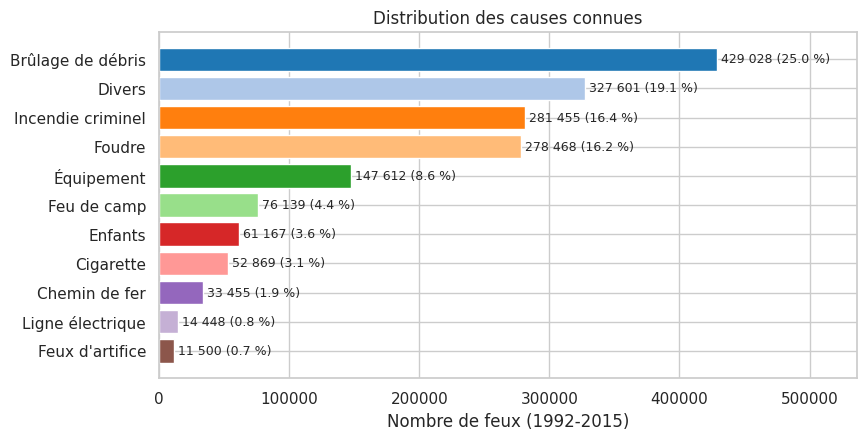

Rapport entre la cause la plus fréquente et la plus rare : 37


In [14]:
connues = cibles[~cibles["cause"].str.startswith("(")]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(connues["cause"][::-1], connues["count"][::-1], color=[PALETTE[c] for c in connues["cause"][::-1]])
for i, (v, p) in enumerate(zip(connues["count"][::-1], connues["part_connues_pct"][::-1])):
    ax.text(v, i, f" {v:,} ({p:.1f} %)".replace(",", " "), va="center", fontsize=9)
ax.set_xlabel("Nombre de feux (1992-2015)"); ax.set_xlim(0, connues["count"].max() * 1.25)
ax.set_title("Distribution des causes connues")
plt.show()
print(f"Rapport entre la cause la plus fréquente et la plus rare : {connues['count'].max() / connues['count'].min():.0f}")

**Déséquilibre fort.** Quatre causes (brûlage de débris, divers, incendie criminel, foudre) représentent **76,8 %** des feux de cause connue. Les causes « techniques » (chemin de fer, ligne électrique, feux d'artifice) ne pèsent chacune que 0,7 à 2 %, soit un rapport de **37** entre la cause la plus fréquente et la plus rare. L'exactitude seule récompenserait un modèle qui ignore les petites classes : la métrique principale sera le **F1 macro**.

### 4.2 Évolution annuelle

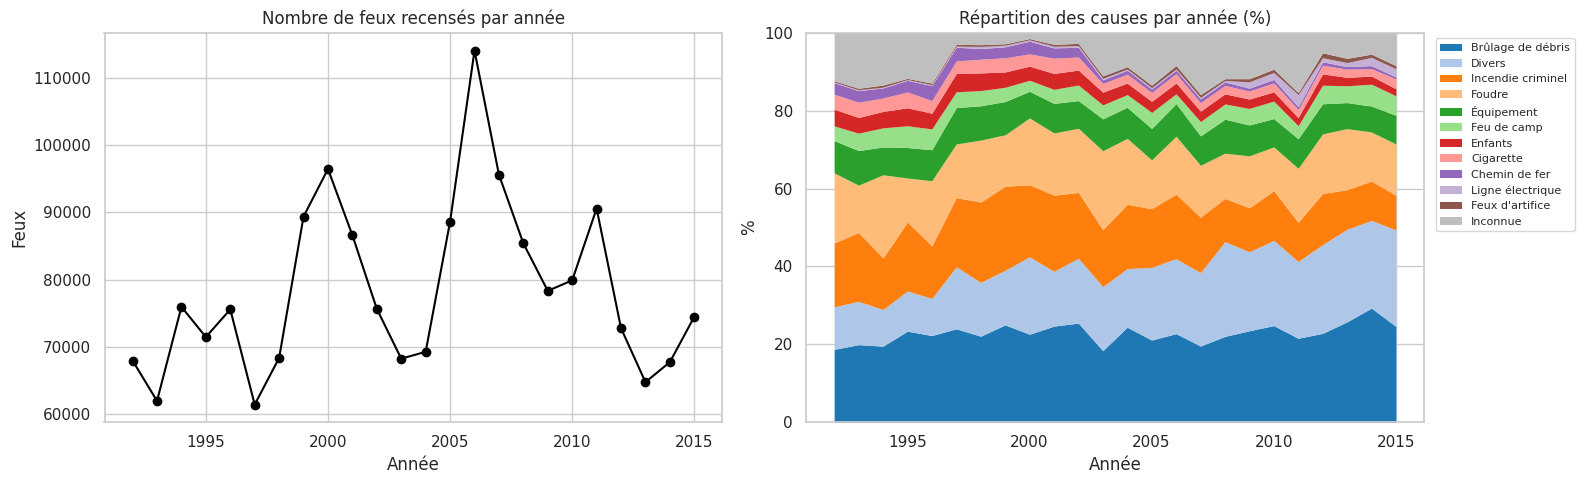

annee              1992  1997  2003  2009  2012  2015
cause                                                
Brûlage de débris  18.7  24.0  18.4  23.5  22.8  24.6
Divers             10.9  15.9  16.4  20.3  22.8  24.8
Incendie criminel  16.4  17.8  14.7  11.3  13.1   8.9
Foudre             18.0  13.7  20.3  13.3  15.3  13.2
Équipement          8.3   9.3   8.2   7.9   7.7   7.4
Feu de camp         3.8   4.1   3.6   4.2   4.8   5.0
Enfants             4.3   4.7   3.3   2.4   2.9   1.8
Cigarette           3.9   3.2   2.2   2.1   2.2   2.5
Chemin de fer       2.9   3.5   0.9   0.7   0.9   0.5
Ligne électrique    0.2   0.3   0.4   1.6   1.1   2.1
Feux d'artifice     0.3   0.4   0.7   0.8   1.3   0.8
Inconnue           12.3   3.0  11.0  11.8   5.1   8.4


In [15]:
an = part_par("annee", connues=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
an.sum(axis=1).plot(ax=axes[0], marker="o", color="black")
axes[0].set_title("Nombre de feux recensés par année"); axes[0].set_xlabel("Année"); axes[0].set_ylabel("Feux")
parts_an = an.div(an.sum(axis=1), axis=0)[ORDRE_CAUSES + ["Inconnue"]] * 100
parts_an.plot.area(ax=axes[1], color=[PALETTE[c] for c in parts_an.columns], linewidth=0)
axes[1].set_title("Répartition des causes par année (%)"); axes[1].set_xlabel("Année"); axes[1].set_ylabel("%")
axes[1].legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8); axes[1].set_ylim(0, 100)
plt.tight_layout(); plt.show()
print(parts_an.round(1).loc[[1992, 1997, 2003, 2009, 2012, 2015]].T.to_string())

**La répartition des causes dérive dans le temps.**
- « Divers » passe de **10,9 % (1992) à 24,8 % (2015)**, et l'incendie criminel de 16,4 % à 8,9 %.
- Le chemin de fer tombe de 2,9 % à 0,5 %, tandis que la ligne électrique passe de 0,2 % à 2,1 %.
- La part de causes **inconnues** varie fortement d'une année à l'autre (3,0 % en 1997, 12,3 % en 1992).

Ces variations reflètent autant les **changements de pratiques de déclaration** (systèmes, catégories) que des changements réels. C'est l'argument principal du **découpage temporel** : un modèle déployé verra une répartition différente de celle de son entraînement.

### 4.3 Saison, jour de la semaine, heure

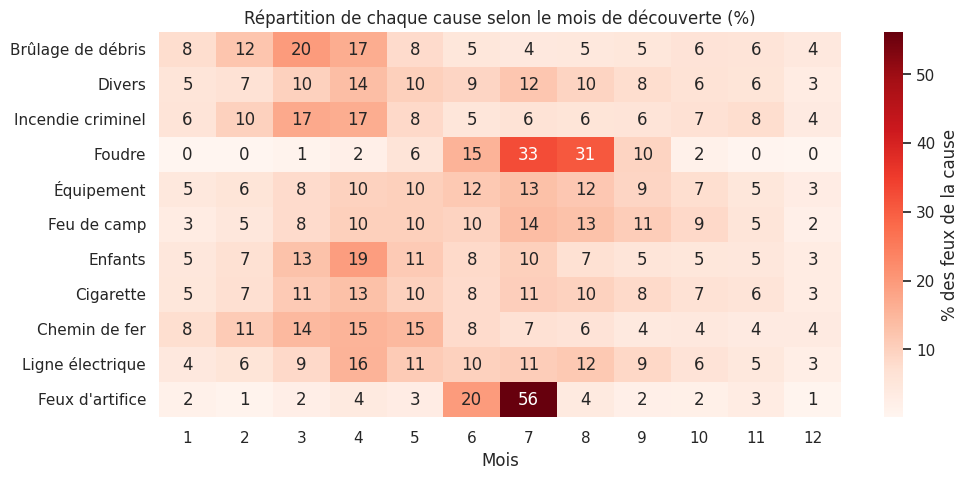

In [16]:
mois = part_par("mois")
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap((mois.div(mois.sum(axis=0), axis=1).T * 100).loc[ORDRE_CAUSES], cmap="Reds", annot=True, fmt=".0f",
            ax=ax, cbar_kws={"label": "% des feux de la cause"})
ax.set_title("Répartition de chaque cause selon le mois de découverte (%)"); ax.set_xlabel("Mois"); ax.set_ylabel("")
plt.show()

**La saison est très discriminante pour certaines causes.**
- **Foudre** : **64 %** des feux en juillet-août (33 % + 31 %), presque aucun de novembre à mars.
- **Feux d'artifice** : **56 % en juillet** (fête nationale du 4 juillet) et 20 % en juin.
- **Brûlage de débris** : pic au **printemps** (20 % en mars, 17 % en avril), quand on brûle les résidus avant la reprise de la végétation. L'incendie criminel a le même profil (17 % en mars et en avril), et les enfants culminent en avril (19 %).
- Les autres causes humaines (équipement, cigarette, feu de camp) sont plus étalées sur l'année.

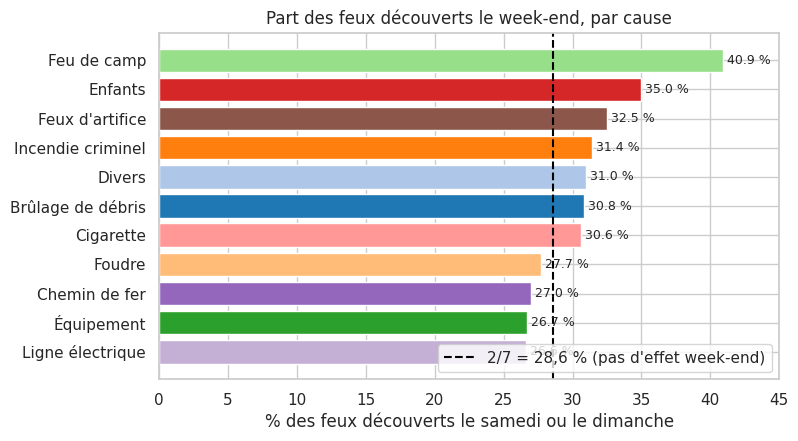

In [17]:
js = part_par("week_end")
part_we = (js.loc[1.0] / js.sum(axis=0) * 100).loc[ORDRE_CAUSES].sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(part_we.index, part_we.values, color=[PALETTE[c] for c in part_we.index])
ax.axvline(100 * 2 / 7, ls="--", color="black", label="2/7 = 28,6 % (pas d'effet week-end)")
for i, v in enumerate(part_we.values):
    ax.text(v, i, f" {v:.1f} %", va="center", fontsize=9)
ax.set_xlabel("% des feux découverts le samedi ou le dimanche"); ax.set_xlim(0, 45)
ax.set_title("Part des feux découverts le week-end, par cause"); ax.legend(loc="lower right")
plt.show()

Sans effet du week-end, on attendrait 2/7 = 28,6 % des feux le samedi ou le dimanche.
- Les causes **liées aux loisirs** dépassent nettement ce niveau : **feu de camp 40,9 %**, enfants 35,0 %, feux d'artifice 32,5 %.
- Les causes **non liées au calendrier humain** (foudre 27,7 %) ou **liées au travail** (équipement 26,7 %, chemin de fer 27,0 %) sont légèrement en dessous.

L'effet existe mais reste modéré : le week-end ne départagera que quelques causes.

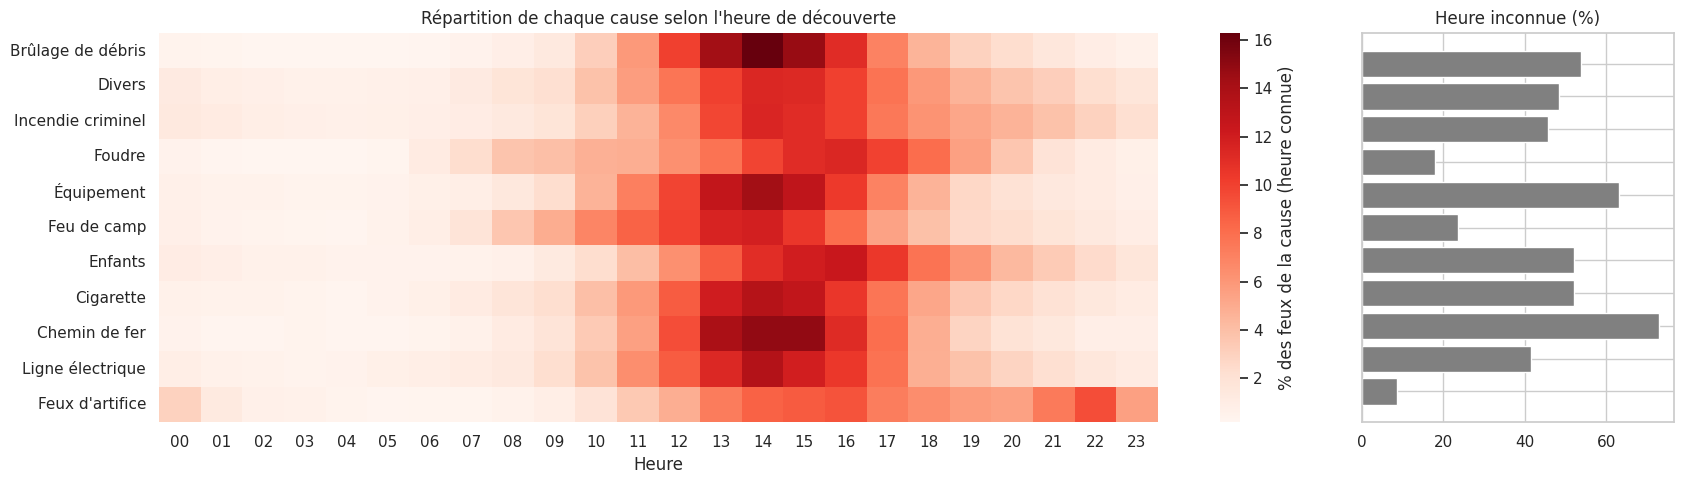

Heure de découverte la plus fréquente par cause : {'Brûlage de débris': '14', 'Divers': '14', 'Incendie criminel': '14', 'Foudre': '16', 'Équipement': '14', 'Feu de camp': '14', 'Enfants': '16', 'Cigarette': '14', 'Chemin de fer': '14', 'Ligne électrique': '14', "Feux d'artifice": '22'}
Part d'heure inconnue par cause (%) : {'Brûlage de débris': 53.8, 'Divers': 48.5, 'Incendie criminel': 45.7, 'Foudre': 18.0, 'Équipement': 63.2, 'Feu de camp': 23.6, 'Enfants': 52.0, 'Cigarette': 52.1, 'Chemin de fer': 73.0, 'Ligne électrique': 41.4, "Feux d'artifice": 8.7}


In [18]:
h = part_par("heure_cat")
h_connue = h.drop(index="inconnue")
fig, axes = plt.subplots(1, 2, figsize=(17, 5), gridspec_kw={"width_ratios": [4, 1]})
sns.heatmap((h_connue.div(h_connue.sum(axis=0), axis=1).T * 100).loc[ORDRE_CAUSES], cmap="Reds", ax=axes[0],
            cbar_kws={"label": "% des feux de la cause (heure connue)"})
axes[0].set_title("Répartition de chaque cause selon l'heure de découverte"); axes[0].set_xlabel("Heure"); axes[0].set_ylabel("")
inc = (h.loc["inconnue"] / h.sum(axis=0) * 100).loc[ORDRE_CAUSES]
axes[1].barh(inc.index[::-1], inc.values[::-1], color="grey"); axes[1].set_title("Heure inconnue (%)")
axes[1].set_yticklabels([])
plt.tight_layout(); plt.show()
pic = (h_connue.idxmax(axis=0)).loc[ORDRE_CAUSES]
print("Heure de découverte la plus fréquente par cause :", pic.to_dict())
print("Part d'heure inconnue par cause (%) :", inc.round(1).to_dict())

- L'heure de découverte la plus fréquente est **14 h** pour la plupart des causes, **16 h pour la foudre** (orages de l'après-midi) et les enfants, et **22 h pour les feux d'artifice**.
- **La part d'heure inconnue dépend fortement de la cause** : 8,7 % pour les feux d'artifice et 18,0 % pour la foudre, contre **73,0 % pour le chemin de fer** et 63,2 % pour l'équipement. Ce manque n'est pas aléatoire : il dépend du système de déclaration (les services fédéraux, très présents sur la foudre, renseignent l'heure).

C'est pourquoi l'heure manquante est gardée comme **modalité `inconnue`** plutôt qu'imputée.

### 4.4 Géographie

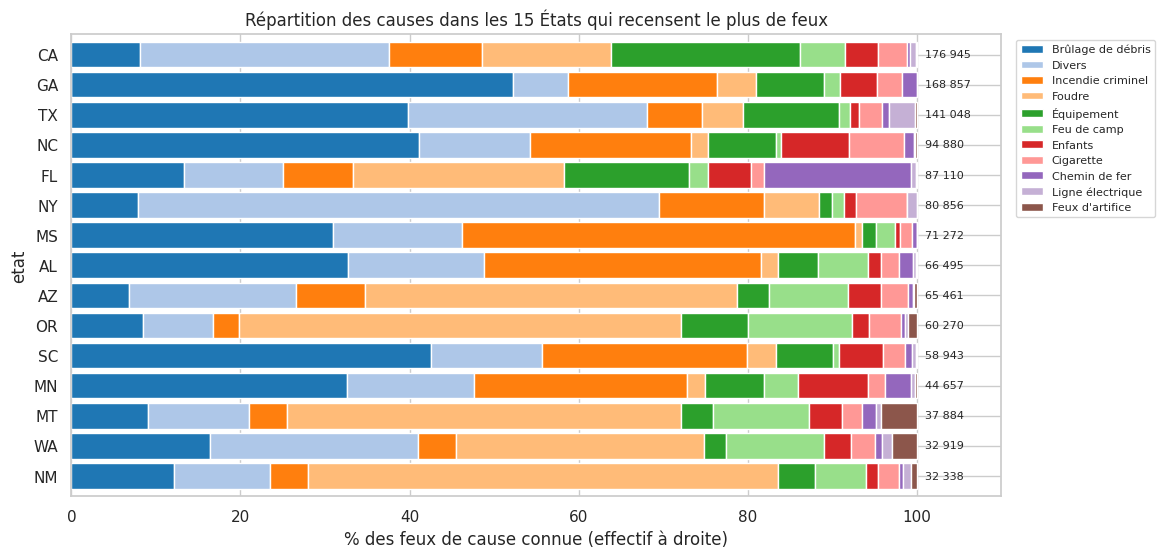

etat,CA,GA,TX,NC,FL,NY,MS,AL,AZ,OR,SC,MN,MT,WA,NM
cause dominante,Divers,Brûlage de débris,Brûlage de débris,Brûlage de débris,Foudre,Divers,Incendie criminel,Incendie criminel,Foudre,Foudre,Brûlage de débris,Brûlage de débris,Foudre,Foudre,Foudre
part_%,29.4,52.2,39.8,41.1,25.0,61.5,46.5,32.8,44.0,52.4,42.6,32.6,46.5,29.4,55.7


In [19]:
et = part_par("etat")
top_etats = et.sum(axis=1).sort_values(ascending=False).head(15).index
parts_et = et.loc[top_etats].div(et.loc[top_etats].sum(axis=1), axis=0)[ORDRE_CAUSES] * 100
fig, ax = plt.subplots(figsize=(12, 6))
parts_et[::-1].plot.barh(stacked=True, ax=ax, color=[PALETTE[c] for c in ORDRE_CAUSES], width=0.85)
for i, e in enumerate(top_etats[::-1]):
    ax.text(101, i, f"{int(et.loc[e].sum()):,}".replace(",", " "), va="center", fontsize=8)
ax.set_xlim(0, 110); ax.set_xlabel("% des feux de cause connue (effectif à droite)")
ax.set_title("Répartition des causes dans les 15 États qui recensent le plus de feux")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()
dominante = pd.DataFrame({"cause dominante": parts_et.idxmax(axis=1), "part_%": parts_et.max(axis=1).round(1)})
dominante.T

**Forte structure géographique**, liée aussi aux pratiques des États :
- Dans l'Ouest, la foudre domine (Nouveau-Mexique 55,7 %, Oregon 52,4 %, Montana 46,5 %, Arizona 44,0 %).
- Dans le Sud-Est, c'est le brûlage de débris (Géorgie 52,2 %, Caroline du Nord 41,1 %) et l'incendie criminel (Mississippi 46,5 %).
- **New York classe 61,5 % de ses feux en « Divers »** : c'est typiquement un effet de déclaration, et non un « risque Divers » propre à cet État.

La règle « cause dominante de l'État » sera donc une référence sérieuse.

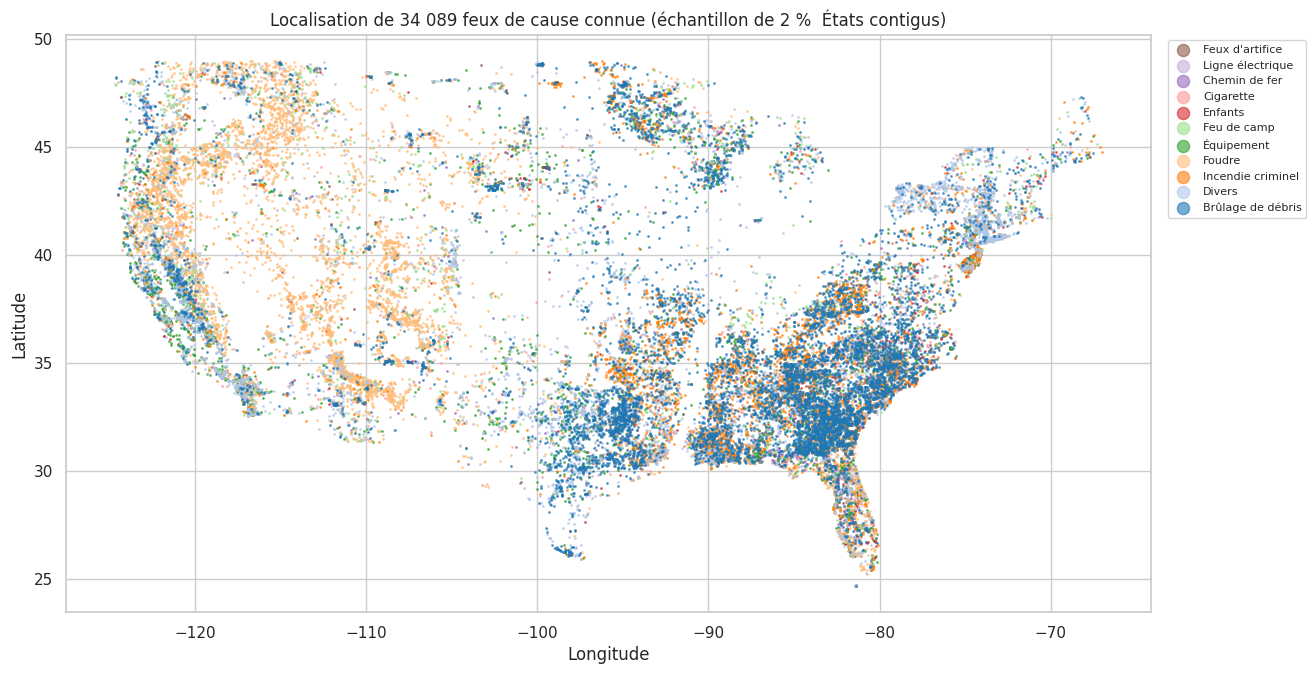

In [20]:
# Carte : échantillon aléatoire de feux de cause connue (pas de toPandas sur les données complètes)
ech = (df_eda.where("cause IS NOT NULL AND lon > -130 AND lat < 50 AND lat > 24")   # États contigus
       .sample(fraction=0.02, seed=SEED).select("lat", "lon", "cause").toPandas())
fig, ax = plt.subplots(figsize=(14, 7.5))
for c in ORDRE_CAUSES[::-1]:
    d = ech[ech["cause"] == c]
    ax.scatter(d["lon"], d["lat"], s=1.2, color=PALETTE[c], label=c, alpha=0.6)
ax.set_title(f"Localisation de {len(ech):,} feux de cause connue (échantillon de 2 %, États contigus)".replace(",", " "))
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.legend(markerscale=8, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()

Sur l'échantillon de 34 089 feux :
- l'**intérieur de l'Ouest** (Rocheuses, Grand Bassin) est dominé par la **foudre** ;
- le **Sud-Est** (de la Géorgie à l'est du Texas) par le **brûlage de débris** et l'**incendie criminel**, avec une densité de feux très élevée ;
- le **Nord-Est** est dominé par « Divers ».

La latitude et la longitude porteront donc beaucoup d'information, et une forêt peut découper ces zones directement.

### 4.5 Type de propriétaire du terrain

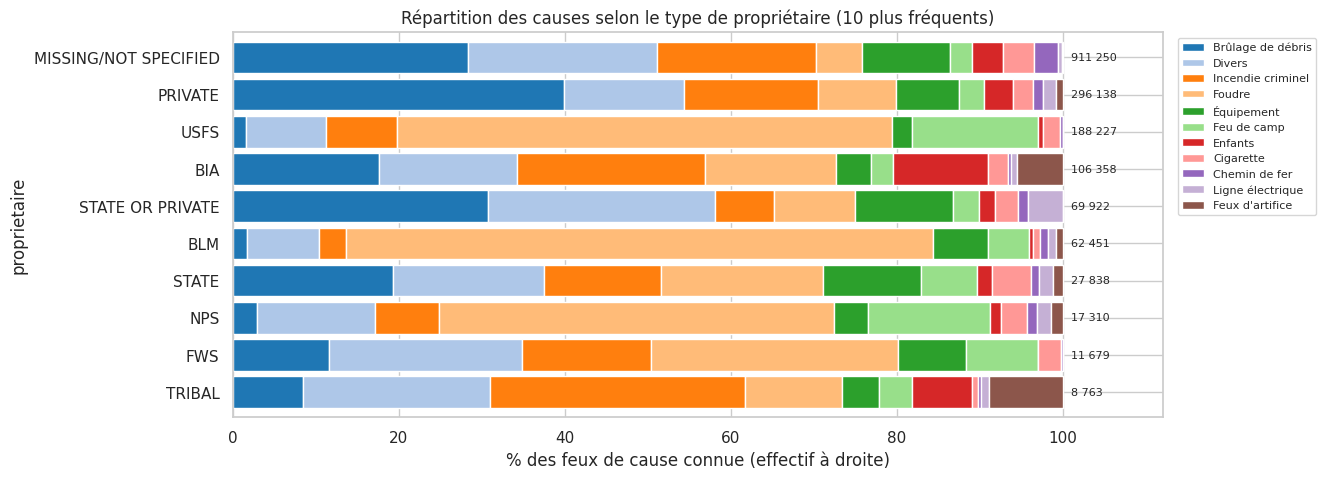

cause,Foudre,Brûlage de débris,Incendie criminel,Feu de camp
proprietaire,,,,
MISSING/NOT SPECIFIED,5.5,28.3,19.1,2.6
PRIVATE,9.4,39.9,16.1,3.1
USFS,59.7,1.6,8.5,15.1
BIA,15.8,17.6,22.6,2.7
STATE OR PRIVATE,9.8,30.8,7.2,3.1
BLM,70.7,1.7,3.3,5.0
STATE,19.5,19.3,14.0,6.7
NPS,47.6,3.0,7.7,14.7
FWS,29.8,11.6,15.5,8.7


In [21]:
pr = part_par("proprietaire")
top_pr = pr.sum(axis=1).sort_values(ascending=False).head(10).index
parts_pr = pr.loc[top_pr].div(pr.loc[top_pr].sum(axis=1), axis=0)[ORDRE_CAUSES] * 100
fig, ax = plt.subplots(figsize=(12, 5))
parts_pr[::-1].plot.barh(stacked=True, ax=ax, color=[PALETTE[c] for c in ORDRE_CAUSES], width=0.85)
for i, p in enumerate(top_pr[::-1]):
    ax.text(101, i, f"{int(pr.loc[p].sum()):,}".replace(",", " "), va="center", fontsize=8)
ax.set_xlim(0, 112); ax.set_xlabel("% des feux de cause connue (effectif à droite)")
ax.set_title("Répartition des causes selon le type de propriétaire (10 plus fréquents)")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
plt.show()
parts_pr[["Foudre", "Brûlage de débris", "Incendie criminel", "Feu de camp"]].round(1)

- Sur les **terres fédérales**, la foudre domine : **BLM 70,7 %**, **USFS 59,7 %**, NPS 47,6 %. Ces terres sont vastes et isolées. Le feu de camp y est aussi plus fréquent (15,1 % sur USFS, 14,7 % sur NPS).
- Sur les terrains **privés**, c'est le brûlage de débris (39,9 %).
- Sur les terres **tribales**, l'incendie criminel (30,6 %).
- La modalité « MISSING/NOT SPECIFIED » (56 % des feux, surtout déclarés par les États) ressemble aux terrains privés : brûlage 28,3 %, incendie criminel 19,1 %.

In [22]:
df_eda.unpersist()   # fin de l'EDA : on libère la mémoire pour la modélisation

DataFrame[cause: string, annee: int, mois: int, jour_semaine: int, week_end: decimal(2,1), heure: int, heure_cat: string, lat: double, lon: double, etat: string, proprietaire: string, organisme: string, type_source: string, unite: string, cellule: string, FIRE_YEAR: bigint]

Le cache de l'EDA est libéré : la mémoire est réservée aux vecteurs de modélisation.

## 5. Prétraitement

Les transformations sont des **expressions Spark SQL natives** (`src/preparation.py`), exécutées dans la JVM sans sérialisation vers Python (une UDF Python serait plusieurs fois plus lente sur 1,9 M lignes). Elles sont regroupées dans un `SQLTransformer`, qui sera la **première étape du pipeline sauvegardé** : le modèle déployé applique exactement le même nettoyage à une saisie brute.

In [23]:
print(prep.requete_preparation()[:900], "...")

SELECT *, year(date_decouverte) AS annee, month(date_decouverte) AS mois, dayofyear(date_decouverte) AS jour_annee, dayofweek(date_decouverte) AS jour_semaine, CASE WHEN dayofweek(date_decouverte) IN (1, 7) THEN 1.0 ELSE 0.0 END AS week_end, COALESCE(lpad(CAST(heure AS STRING), 2, '0'), 'inconnue') AS heure_cat, CASE WHEN lat IS NULL OR lon IS NULL THEN 'INCONNU' ELSE concat(CAST(floor(lat / 1.0) * 1.0 AS STRING), '_', CAST(floor(lon / 1.0) * 1.0 AS STRING)) END AS cellule FROM (SELECT *, date_add(DATE'1970-01-01', CAST(DISCOVERY_DATE - 2440587.5 AS INT)) AS date_decouverte, CASE WHEN DISCOVERY_TIME RLIKE '^[0-9]{4}$' AND CAST(substr(DISCOVERY_TIME, 1, 2) AS INT) BETWEEN 0 AND 23 AND CAST(substr(DISCOVERY_TIME, 3, 2) AS INT) BETWEEN 0 AND 59 THEN CAST(substr(DISCOVERY_TIME, 1, 2) AS INT) END AS heure, CASE WHEN LATITUDE BETWEEN 17.0 AND 72.0 THEN CAST(LATITUDE AS DOUBLE) END AS lat, CASE ...


In [24]:
# Tests sur un petit DataFrame saisi à la main (format brut du fichier source)
from pyspark.sql import Row

def jour_julien(date_iso):
    return (pd.Timestamp(date_iso) - pd.Timestamp("1970-01-01")).days + prep.JOUR_JULIEN_EPOCH

tests = spark.createDataFrame([
    Row(DISCOVERY_DATE=2453403.5, DISCOVERY_TIME="1300", LATITUDE=40.04, LONGITUDE=-121.01, STATE="CA",
        OWNER_DESCR="USFS", NWCG_REPORTING_AGENCY="FS", SOURCE_SYSTEM_TYPE="FED", NWCG_REPORTING_UNIT_ID="USCAPNF"),
    Row(DISCOVERY_DATE=jour_julien("2015-07-04"), DISCOVERY_TIME="0845", LATITUDE=95.0, LONGITUDE=-80.0, STATE=" ga ",
        OWNER_DESCR=None, NWCG_REPORTING_AGENCY="ST/C&L", SOURCE_SYSTEM_TYPE="NONFED", NWCG_REPORTING_UNIT_ID="USGAGAS"),
    Row(DISCOVERY_DATE=jour_julien("2010-01-03"), DISCOVERY_TIME=None, LATITUDE=64.8, LONGITUDE=-147.7, STATE="AK",
        OWNER_DESCR="BLM", NWCG_REPORTING_AGENCY="BLM", SOURCE_SYSTEM_TYPE="FED", NWCG_REPORTING_UNIT_ID="USAKAKS"),
    Row(DISCOVERY_DATE=jour_julien("2010-01-04"), DISCOVERY_TIME="2460", LATITUDE=18.2, LONGITUDE=-200.0, STATE="PR",
        OWNER_DESCR="  private  ", NWCG_REPORTING_AGENCY="FWS", SOURCE_SYSTEM_TYPE="FED", NWCG_REPORTING_UNIT_ID="USPRXXX"),
])
res = [r.asDict() for r in prep.preparer(tests).collect()]

# Date julienne -> date classique (1er exemple : la 1re ligne du fichier, 33e jour de 2005)
assert str(res[0]["date_decouverte"]) == "2005-02-02" and res[0]["jour_annee"] == 33
assert (res[0]["annee"], res[0]["mois"], res[0]["jour_semaine"], res[0]["week_end"]) == (2005, 2, 4, 0.0)   # mercredi
assert str(res[1]["date_decouverte"]) == "2015-07-04" and res[1]["week_end"] == 1.0                    # samedi
assert res[2]["jour_semaine"] == 1 and res[2]["week_end"] == 1.0                                       # dimanche
# Heure : '1300' -> 13 ; '0845' -> 8 ; manquante ou invalide ('2460') -> NULL et 'inconnue'
assert [r["heure"] for r in res] == [13, 8, None, None]
assert [r["heure_cat"] for r in res] == ["13", "08", "inconnue", "inconnue"]
# Coordonnées hors bornes -> NULL ; cellule de 1° ; cellule INCONNU si une coordonnée manque
assert res[1]["lat"] is None and res[3]["lon"] is None and res[0]["lat"] == 40.04
assert res[0]["cellule"] == "40.0_-122.0" and res[2]["cellule"] == "64.0_-148.0" and res[1]["cellule"] == "INCONNU"
# Catégories : majuscules, espaces retirés, NULL -> INCONNU
assert res[1]["etat"] == "GA" and res[1]["proprietaire"] == "INCONNU" and res[3]["proprietaire"] == "PRIVATE"

# Cible
cibles_test = spark.createDataFrame([Row(STAT_CAUSE_DESCR=v) for v in
                                     ["Lightning", "Structure", "Missing/Undefined", "Fireworks"]])
assert [r["cause"] for r in prep.ajouter_cause(cibles_test).collect()] == ["Foudre", "Divers", None, "Feux d'artifice"]

# Regroupement des modalités rares
reg = prep.transformateur_regroupement({"etat": ["CA", "AK"]})
assert [r["etat_g"] for r in reg.transform(prep.preparer(tests)).collect()] == ["CA", "AUTRE", "AK", "AUTRE"]
print("Toutes les assertions passent.")

Toutes les assertions passent.


**Toutes les assertions passent** sur des cas réels ou limites : conversion de la date julienne (2453403.5 → 2 février 2005, un mercredi), samedi et dimanche, heure `'2460'` invalide → `inconnue`, coordonnées hors bornes, normalisation des catégories, regroupement des rares, et `Feux d'artifice` avec apostrophe.

Ces tests ont d'ailleurs détecté un vrai bogue : en Spark SQL, `'Feux d''artifice'` n'échappe pas l'apostrophe, il concatène deux littéraux (« Feux dartifice »). D'où la fonction `litteral_sql`, qui échappe avec un antislash.

In [25]:
# Contrôles sur les données complètes, en une passe
prepare = prep.preparer(df_brut)
ctrl = prepare.agg(
    F.sum((F.col("annee") != F.col("FIRE_YEAR")).cast("int")).alias("annee_differente_de_FIRE_YEAR"),
    F.sum((F.col("jour_annee") != F.col("DISCOVERY_DOY")).cast("int")).alias("jour_different_de_DISCOVERY_DOY"),
    F.sum(F.col("lat").isNull().cast("int")).alias("lat_hors_bornes"),
    F.sum(F.col("lon").isNull().cast("int")).alias("lon_hors_bornes"),
    F.sum((F.col("DISCOVERY_TIME").isNotNull() & F.col("heure").isNull()).cast("int")).alias("heure_renseignee_invalide"),
    F.avg((F.col("heure_cat") == "inconnue").cast("int")).alias("part_heure_inconnue"),
    F.avg((F.col("proprietaire") == "MISSING/NOT SPECIFIED").cast("int")).alias("part_proprietaire_non_specifie"),
    F.countDistinct("cellule").alias("cellules_1deg"),
).collect()[0].asDict()
pd.Series(ctrl).to_frame("valeur")

,valeur
annee_differente_de_FIRE_YEAR,4.000000
jour_different_de_DISCOVERY_DOY,0.000000
lat_hors_bornes,0.000000
lon_hors_bornes,0.000000
heure_renseignee_invalide,0.000000
part_heure_inconnue,0.469372
part_proprietaire_non_specifie,0.558817
cellules_1deg,1227.000000


**Contrôles sur 1,88 M lignes.**
- L'année calculée depuis la date julienne diffère de `FIRE_YEAR` pour **4 feux seulement**, et le jour de l'année est identique partout : la conversion est validée.
- Aucune coordonnée hors bornes, aucune heure renseignée invalide.
- 46,9 % d'heures inconnues et 55,9 % de propriétaires non spécifiés : deux modalités à part entière, et non des erreurs.
- La grille de 1° compte **1 227 cellules** occupées.

**Stratégie de valeurs manquantes, variable par variable.**

| Variable | Manquants | Stratégie | Justification |
|---|---|---|---|
| Heure de découverte | voir ci-dessus | modalité `inconnue` | le manque n'est pas aléatoire : il dépend de l'organisme déclarant |
| Propriétaire | modalité `MISSING/NOT SPECIFIED` déjà présente | conservée telle quelle | idem : marqueur du système de déclaration |
| Latitude, longitude | aucun hors bornes | `Imputer` (médiane) dans le pipeline | sécurité pour le déploiement (saisie incomplète) |
| État, organisme, type de source, unité | aucun | `INCONNU` si vide (déploiement) | |
| Comté (`COUNTY`, `FIPS_*`) | 36,1 % | **non utilisé** | redondant avec latitude/longitude et la cellule |

**Grille spatiale de 1°.** Une cellule mesure environ 111 km × 85 km à 40° N. C'est plus fin que l'État, et assez grand pour que la plupart des cellules contiennent des centaines de feux. Elle sert surtout à la régression logistique, qui ne peut pas découper latitude et longitude en zones ; la forêt découpe directement les coordonnées. Un pas de 0,5° quadruplerait le nombre de cellules, et donc les modalités rares.

## 6. Découpage temporel et pipeline

### 6.1 Découpage

Un modèle déployé prédit la cause de feux **futurs**. On entraîne donc sur le passé et on évalue sur des années postérieures. Un découpage aléatoire mélangerait les années et surestimerait la performance, puisque les pratiques de déclaration évoluent dans le temps (section 4.2).

In [26]:
ANNEES = {"entrainement": (1992, 2009), "validation": (2010, 2012), "test": (2013, 2015)}
connu = df_cause.where("cause IS NOT NULL")
inconnu = df_cause.where("cause IS NULL")
train = connu.where(F.col("FIRE_YEAR").between(*ANNEES["entrainement"]))
val = connu.where(F.col("FIRE_YEAR").between(*ANNEES["validation"]))
test = connu.where(F.col("FIRE_YEAR").between(*ANNEES["test"]))

effectifs = (connu.withColumn("jeu", F.when(F.col("FIRE_YEAR") <= 2009, "entrainement")
                              .when(F.col("FIRE_YEAR") <= 2012, "validation").otherwise("test"))
             .groupBy("jeu", "cause").count().toPandas().pivot(index="cause", columns="jeu", values="count"))
effectifs = effectifs[["entrainement", "validation", "test"]]
print("Effectifs :", effectifs.sum().to_dict(), "| feux de cause inconnue (toutes années) :", inconnu.count())
(effectifs / effectifs.sum() * 100).round(1).loc[ORDRE_CAUSES]

Effectifs : {'entrainement': 1302822, 'validation': 218114, 'test': 192806} | feux de cause inconnue (toutes années) : 166723


jeu,entrainement,validation,test
cause,,,
Brûlage de débris,24.4,25.7,28.5
Divers,17.4,23.8,25.5
Incendie criminel,17.8,13.2,10.4
Foudre,16.7,15.0,14.8
Équipement,8.8,8.4,7.4
Feu de camp,4.3,4.6,5.4
Enfants,3.9,2.7,2.2
Cigarette,3.3,2.4,2.3
Chemin de fer,2.3,0.9,0.7


**Découpage temporel retenu.**
- **Entraînement 1992-2009** : 1 302 822 feux.
- **Validation 2010-2012** : 218 114 feux.
- **Test 2013-2015** : 192 806 feux.
- Feux de cause inconnue (toutes années) : 166 723, mis à part.

La dérive est visible : « Divers » passe de 17,4 % (entraînement) à 25,5 % (test), l'incendie criminel de 17,8 % à 10,4 %, la ligne électrique de 0,4 % à 1,9 %. Le test est donc **plus difficile** qu'un test aléatoire, mais il est **réaliste** pour un modèle déployé.

### 6.2 Pipeline `pyspark.ml`

In [27]:
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.feature import Imputer, IndexToString, OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler

NUM = ["lat", "lon", "jour_annee", "mois", "jour_semaine", "week_end"]
CAT_RF = ["etat", "proprietaire", "organisme", "type_source", "heure_cat", "unite_g"]
CAT_LR = CAT_RF + ["cellule_g", "mois", "jour_semaine"]       # mois et jour en one-hot pour le modèle linéaire
SEUILS = {"unite": 2000, "cellule": 1000}                      # effectif minimal dans l'entraînement

# Étiquette : index des causes appris sur l'entraînement (ordre = fréquence décroissante)
indexeur_cause = StringIndexer(inputCol="cause", outputCol="label").fit(train)
CLASSES = list(indexeur_cause.labels)
K = len(CLASSES)
print("Classes (ordre des index) :", CLASSES)


def construire_pre(df_fit: "DataFrame") -> PipelineModel:
    """Ajuste toutes les étapes de préparation sur `df_fit` UNIQUEMENT (regroupements, index, imputation, échelle)."""
    prepare_fit = prep.preparer(df_fit)
    frequentes = {c: prep.modalites_frequentes(prepare_fit, c, s) for c, s in SEUILS.items()}
    etapes = ([prep.transformateur_preparation(), prep.transformateur_regroupement(frequentes)]
              + [StringIndexer(inputCol=c, outputCol=f"{c}_i", handleInvalid="keep") for c in dict.fromkeys(CAT_LR)]
              + [Imputer(inputCols=NUM, outputCols=[f"{c}_imp" for c in NUM], strategy="median"),
                 OneHotEncoder(inputCols=[f"{c}_i" for c in CAT_LR], outputCols=[f"{c}_oh" for c in CAT_LR],
                               handleInvalid="keep"),
                 VectorAssembler(inputCols=[f"{c}_imp" for c in NUM] + [f"{c}_i" for c in CAT_RF], outputCol="f_rf"),
                 VectorAssembler(inputCols=[f"{c}_imp" for c in NUM if c not in ("mois", "jour_semaine")]
                                 + [f"{c}_oh" for c in CAT_LR], outputCol="f_lr_brut"),
                 StandardScaler(inputCol="f_lr_brut", outputCol="f_lr", withMean=False)])
    return Pipeline(stages=etapes).fit(df_fit)


def poids_classes(df_label) -> dict:
    """Poids inversement proportionnels à la fréquence : n / (K * n_c), calculés sur le jeu d'ajustement."""
    comptes = dict(df_label.groupBy("label").count().collect())
    total = sum(comptes.values())
    return {int(k): total / (K * v) for k, v in comptes.items()}


def vecteurs(pre: PipelineModel, df, poids: dict):
    """Étiquette, poids et vecteurs de variables (pour RF et régression logistique)."""
    carte = F.create_map(*[x for k, v in poids.items() for x in (F.lit(float(k)), F.lit(v))])
    return (pre.transform(indexeur_cause.transform(df))
            .withColumn("poids", carte[F.col("label")]).select("label", "poids", "f_rf", "f_lr"))


t0 = time.time()
pre_train = construire_pre(train)
POIDS = poids_classes(indexeur_cause.transform(train))
# Mise en cache des vecteurs : chaque modèle de la grille relit ces données plusieurs fois
train_v = vecteurs(pre_train, train, POIDS).cache()
val_v = vecteurs(pre_train, val, POIDS).cache()
print(f"Préparation + mise en cache : {train_v.count()} + {val_v.count()} lignes en {time.time() - t0:.0f} s")

regroupeur = pre_train.stages[1].getStatement()
idx = {s.getInputCol(): len(s.labels) for s in pre_train.stages if hasattr(s, "labels") and hasattr(s, "getInputCol")}
print("Modalités après regroupement (hors 'AUTRE' et index inconnu) :",
      {c: idx[c] for c in ["unite_g", "cellule_g", "etat", "proprietaire", "organisme", "heure_cat"]})
MAX_BINS = max(32, max(idx[c] + 1 for c in CAT_RF))
print("Taille du vecteur RF :", len(NUM) + len(CAT_RF), "| vecteur LR :", train_v.first()["f_lr"].size, "| maxBins :", MAX_BINS)
print("Poids des classes :", {CLASSES[k]: round(v, 2) for k, v in sorted(POIDS.items())})

Classes (ordre des index) : ['Brûlage de débris', 'Incendie criminel', 'Divers', 'Foudre', 'Équipement', 'Feu de camp', 'Enfants', 'Cigarette', 'Chemin de fer', "Feux d'artifice", 'Ligne électrique']


Préparation + mise en cache : 1302822 + 218114 lignes en 144 s


Modalités après regroupement (hors 'AUTRE' et index inconnu) : {'unite_g': 111, 'cellule_g': 347, 'etat': 52, 'proprietaire': 16, 'organisme': 10, 'heure_cat': 25}


Taille du vecteur RF : 12 | vecteur LR : 596 | maxBins : 112
Poids des classes : {'Brûlage de débris': 0.37, 'Incendie criminel': 0.51, 'Divers': 0.52, 'Foudre': 0.55, 'Équipement': 1.03, 'Feu de camp': 2.12, 'Enfants': 2.32, 'Cigarette': 2.75, 'Chemin de fer': 3.93, "Feux d'artifice": 15.57, 'Ligne électrique': 20.66}


**Le pipeline est ajusté sur l'entraînement uniquement** : regroupements, index, médianes et échelle. Préparer et mettre en cache 1,52 M lignes prend **144 s**.
- **Regroupements** : 111 unités déclarantes ont au moins 2 000 feux d'entraînement, et 347 cellules de 1° au moins 1 000 ; les autres deviennent `AUTRE`.
- **Forêt** : un vecteur de **12 variables**, dont les catégorielles sous forme d'**index**. Les arbres de MLlib traitent nativement les variables catégorielles, et le one-hot y est inutile. Il faut seulement `maxBins` (112) ≥ le nombre de modalités.
- **Régression logistique** : un vecteur de **596 dimensions** (one-hot), standardisé. Le modèle linéaire exige le one-hot et une échelle homogène.
- **Poids de classes** (`weightCol`), calculés sur l'entraînement : de 0,37 (brûlage de débris) à plus de 20 (ligne électrique).
- **Mise en cache** des vecteurs : chaque modèle de la grille relit ces données à chaque itération ou à chaque niveau d'arbre. Sans cache, Spark referait toute la préparation à chaque passe.

## 7. Modélisation

### 7.1 Références

In [28]:
def evaluer(df_pred, nom):
    m = prep.metriques(prep.matrice_confusion(df_pred), K)
    return {"modèle": nom, "exactitude": m["exactitude"], "F1 macro": m["f1_macro"], "F1 pondéré": m["f1_pondere"]}, m


# (a) classe majoritaire de l'entraînement (index 0 = cause la plus fréquente)
pred_maj_val = val_v.select("label", F.lit(0.0).alias("prediction"))

# (b) cause la plus fréquente de l'État, apprise sur l'entraînement
IDX_CAUSE = F.create_map(*[x for i, c in enumerate(CLASSES) for x in (F.lit(c), F.lit(float(i)))])


def regle_etat(df_fit):
    c = prep.preparer(df_fit).groupBy("etat", "cause").count()
    w = Window.partitionBy("etat").orderBy(F.desc("count"))
    return (c.withColumn("r", F.row_number().over(w)).where("r = 1")
            .select("etat", IDX_CAUSE[F.col("cause")].alias("prediction")))


def appliquer_regle(regle, df):
    """États absents de l'entraînement : classe majoritaire (index 0)."""
    d = prep.preparer(df).withColumn("label", IDX_CAUSE[F.col("cause")])
    return d.join(F.broadcast(regle), "etat", "left").fillna({"prediction": 0.0}).select("label", "prediction")


regle_train = regle_etat(train)
print("Règle par État (extrait) :", dict(list(regle_train.toPandas().assign(
    c=lambda d: d["prediction"].map(lambda i: CLASSES[int(i)])).set_index("etat")["c"].items())[:10]))
resultats_val, details_val = [], {}
for nom, pred in [("Référence : classe majoritaire", pred_maj_val),
                  ("Référence : cause dominante de l'État", appliquer_regle(regle_train, val))]:
    r, m = evaluer(pred, nom); resultats_val.append(r); details_val[nom] = m
pd.DataFrame(resultats_val).round(4)

Règle par État (extrait) : {'AK': 'Foudre', 'AL': 'Incendie criminel', 'AR': 'Incendie criminel', 'AZ': 'Foudre', 'CA': 'Divers', 'CO': 'Foudre', 'CT': 'Divers', 'DC': 'Divers', 'DE': 'Divers', 'FL': 'Foudre'}


,modèle,exactitude,F1 macro,F1 pondéré
0,Référence : classe majoritaire,0.2566,0.0371,0.1048
1,Référence : cause dominante de l'État,0.3862,0.1508,0.3273


**Références sur la validation.**
- **Classe majoritaire** : exactitude 0,257 et **F1 macro 0,037**. Elle ne prédit qu'une classe sur onze.
- **Cause dominante de l'État** : exactitude **0,386**, F1 macro **0,151**. Cette règle triviale est forte en exactitude, car la géographie domine, mais elle ne prédit jamais 7 causes sur 11.

### 7.2 Réglage des hyperparamètres (entraînement → validation)

`TrainValidationSplit` découpe **aléatoirement** les données qu'on lui donne (`trainRatio`) : il ne permet pas d'imposer « entraînement = 1992-2009, validation = 2010-2012 ». On reproduit donc son principe à la main : une seule séparation entraînement/validation, chaque combinaison de la grille ajustée sur l'entraînement et évaluée sur la validation, choix sur le **F1 macro**. La grille est volontairement petite (temps et mémoire mesurés en prototype : environ 2,5 à 5 min par forêt).

**Contrainte mémoire mesurée.** Une forêt de profondeur 15 a été essayée. Son entraînement passe, mais la **prédiction** provoque un `OutOfMemoryError` : en mode local, les 12 tâches désérialisent chacune leur copie du modèle dans le même tas Java de 4 Go, et une forêt de profondeur 15 a jusqu'à 8 fois plus de nœuds qu'une forêt de profondeur 12. La profondeur est donc plafonnée à 12 ; on teste à la place plus d'arbres (60).

In [29]:
from pyspark.ml.classification import LogisticRegression, RandomForestClassifier

grille = (
    [("Régression logistique", {"regParam": r}) for r in [0.0001, 0.001, 0.01]]
    + [("Random forest", {"numTrees": t, "maxDepth": d}) for t, d in [(30, 10), (30, 12), (60, 12)]]
)


def creer_modele(type_modele, params):
    if type_modele == "Régression logistique":
        return LogisticRegression(featuresCol="f_lr", labelCol="label", weightCol="poids", family="multinomial",
                                  maxIter=100, elasticNetParam=0.0, **params)
    return RandomForestClassifier(featuresCol="f_rf", labelCol="label", weightCol="poids", maxBins=MAX_BINS,
                                  maxMemoryInMB=128, subsamplingRate=0.5, featureSubsetStrategy="sqrt",
                                  seed=SEED, **params)


essais, details_grille = [], {}   # on ne garde que les métriques : un modèle de forêt occupe des centaines de Mo
for type_modele, params in grille:
    t0 = time.time()
    modele = creer_modele(type_modele, params).fit(train_v)
    duree = time.time() - t0
    r, m = evaluer(modele.transform(val_v), f"{type_modele} {params}")
    essais.append({**r, "type": type_modele, "params": params, "durée_s": round(duree)})
    details_grille[r["modèle"]] = m
    del modele; liberer_memoire()
    print(f"{r['modèle']:<55} F1 macro {r['F1 macro']:.4f} | exactitude {r['exactitude']:.4f} | {duree:.0f} s")
essais = pd.DataFrame(essais)

Régression logistique {'regParam': 0.0001}              F1 macro 0.2398 | exactitude 0.2974 | 152 s


Régression logistique {'regParam': 0.001}               F1 macro 0.2408 | exactitude 0.2986 | 122 s


Régression logistique {'regParam': 0.01}                F1 macro 0.2415 | exactitude 0.3002 | 62 s


Random forest {'numTrees': 30, 'maxDepth': 10}          F1 macro 0.2365 | exactitude 0.3060 | 172 s


Random forest {'numTrees': 30, 'maxDepth': 12}          F1 macro 0.2513 | exactitude 0.3227 | 305 s


Random forest {'numTrees': 60, 'maxDepth': 12}          F1 macro 0.2511 | exactitude 0.3246 | 569 s


**Grille (temps d'entraînement mesurés).**
- **Régression logistique** : F1 macro 0,240 à 0,242, peu sensible à la régularisation ; 62 à 152 s.
- **Forêt de profondeur 10** : 0,237 (172 s).
- **Forêt de profondeur 12 à 30 arbres** : **0,2513** (305 s).
- **60 arbres** : 0,2511 pour un temps presque doublé (569 s). Ajouter des arbres n'apporte rien : la limite vient des variables, pas de la variance du modèle.

In [30]:
meilleurs = essais.loc[essais.groupby("type")["F1 macro"].idxmax()]
comparaison_val = pd.concat([pd.DataFrame(resultats_val), meilleurs[["modèle", "exactitude", "F1 macro", "F1 pondéré"]]])
print(comparaison_val.round(4).to_string(index=False))

rappels_val = pd.DataFrame({nom: details_grille[nom]["rappel"] for nom in meilleurs["modèle"]}, index=CLASSES)
rappels_val["Réf. État"] = details_val["Référence : cause dominante de l'État"]["rappel"]
print("\nRappel par classe (validation) :")
print(rappels_val.round(3).to_string())

                                        modèle  exactitude  F1 macro  F1 pondéré
                Référence : classe majoritaire      0.2566    0.0371      0.1048
         Référence : cause dominante de l'État      0.3862    0.1508      0.3273
Random forest {'numTrees': 30, 'maxDepth': 12}      0.3227    0.2513      0.3604
      Régression logistique {'regParam': 0.01}      0.3002    0.2415      0.3413

Rappel par classe (validation) :
                   Random forest {'numTrees': 30, 'maxDepth': 12}  Régression logistique {'regParam': 0.01}  Réf. État
Brûlage de débris                                           0.379                                     0.314      0.683
Incendie criminel                                           0.293                                     0.338      0.296
Divers                                                      0.212                                     0.186      0.312
Foudre                                                      0.530                    

**Comparaison sur la validation.**
- La forêt atteint un **F1 macro de 0,251**, contre 0,151 pour la règle par État (**+67 %**) et 0,037 pour la classe majoritaire. Son F1 pondéré est aussi meilleur (0,360 contre 0,327).
- En revanche, son **exactitude est plus faible que celle de la règle par État** (0,323 contre 0,386). C'est l'effet voulu des **poids de classes** : le modèle sacrifie une partie du rappel des grandes classes (brûlage de débris 0,379, contre 0,683 pour la règle) pour **détecter les causes rares**, que la règle ignore totalement. Il atteint par exemple un rappel de 0,610 pour la ligne électrique, 0,568 pour les feux d'artifice et 0,394 pour le feu de camp.
- Pour des enquêteurs, connaître toutes les pistes plausibles vaut mieux que répondre « brûlage de débris » à chaque fois.
- La régression logistique est proche (F1 macro 0,242) et meilleure sur quelques petites classes (enfants, cigarette).

In [31]:
choix = essais.loc[essais["F1 macro"].idxmax()]
TYPE_FINAL, PARAMS_FINAL = choix["type"], choix["params"]
print("Modèle retenu :", TYPE_FINAL, PARAMS_FINAL, f"(F1 macro validation {choix['F1 macro']:.4f})")

Modèle retenu : Random forest {'numTrees': 30, 'maxDepth': 12} (F1 macro validation 0.2513)


**Modèle retenu : random forest, 30 arbres, profondeur 12** (meilleur F1 macro sur la validation).
- Il capte les interactions entre lieu, saison et organisme, comme la combinaison « foudre = Ouest + été + terres fédérales ».
- Il n'exige ni one-hot ni standardisation.
- Ses importances de variables se lisent directement par variable d'origine.

## 8. Évaluation finale

### 8.1 Impact de la taille finale du feu (fuite), mesuré sur la validation

On ajoute la taille finale (log) et la classe de taille aux variables du modèle retenu. La mesure est faite sur la **validation** : le test reste réservé à l'évaluation unique du modèle final.

In [32]:
from pyspark.ml.feature import VectorAssembler as VA

idx_taille = StringIndexer(inputCol="FIRE_SIZE_CLASS", outputCol="classe_taille_i", handleInvalid="keep").fit(train)


def vecteurs_avec_taille(df):
    d = idx_taille.transform(pre_train.transform(indexeur_cause.transform(df)).withColumn("taille_log", F.log1p("FIRE_SIZE")))
    col_in, col_out = ("f_rf", "f_rf_t") if TYPE_FINAL == "Random forest" else ("f_lr", "f_lr_t")
    carte = F.create_map(*[x for k, v in POIDS.items() for x in (F.lit(float(k)), F.lit(v))])
    return (VA(inputCols=[col_in, "taille_log", "classe_taille_i"], outputCol=col_out).transform(d)
            .withColumn("poids", carte[F.col("label")]).select("label", "poids", col_out))


tr_t, va_t = vecteurs_avec_taille(train).cache(), vecteurs_avec_taille(val)
modele_taille = creer_modele(TYPE_FINAL, PARAMS_FINAL)
modele_taille.setFeaturesCol("f_rf_t" if TYPE_FINAL == "Random forest" else "f_lr_t")
t0 = time.time(); m_taille = modele_taille.fit(tr_t); print(f"Entraînement avec taille : {time.time() - t0:.0f} s")
tr_t.unpersist()
r_avec, det_avec = evaluer(m_taille.transform(va_t), "avec taille finale (fuite)")
del m_taille; liberer_memoire()
det_sans = details_grille[choix["modèle"]]
impact = pd.DataFrame([{"variante": "sans taille (modèle retenu)", "exactitude": det_sans["exactitude"],
                        "F1 macro": det_sans["f1_macro"], "F1 pondéré": det_sans["f1_pondere"]},
                       {"variante": "avec taille finale (fuite)", **{k: r_avec[k] for k in ["exactitude", "F1 macro", "F1 pondéré"]}}])
print(impact.round(4).to_string(index=False))
print("\nRappel par classe, sans / avec taille :")
print(pd.DataFrame({"sans": det_sans["rappel"], "avec": det_avec["rappel"]}, index=CLASSES).round(3).to_string())

Entraînement avec taille : 315 s


                   variante  exactitude  F1 macro  F1 pondéré
sans taille (modèle retenu)      0.3227    0.2513      0.3604
 avec taille finale (fuite)      0.3362    0.2574      0.3713

Rappel par classe, sans / avec taille :
                    sans   avec
Brûlage de débris  0.379  0.410
Incendie criminel  0.293  0.295
Divers             0.212  0.226
Foudre             0.530  0.535
Équipement         0.144  0.145
Feu de camp        0.394  0.430
Enfants            0.195  0.199
Cigarette          0.026  0.023
Chemin de fer      0.112  0.100
Feux d'artifice    0.568  0.570
Ligne électrique   0.610  0.601


**Impact de la taille finale (fuite), mesuré sur la validation.**
- Avec la taille, l'exactitude passe de 0,323 à **0,336** (+0,013) et le F1 macro de 0,251 à **0,257** (+0,006).
- Le gain porte surtout sur le brûlage de débris (rappel +0,031) et le feu de camp (+0,036).

Le gain est **réel mais modeste** : la plupart des feux sont petits (classes A et B), là où la taille discrimine peu, et la foudre est déjà repérée par la saison et le lieu.

Elle reste **exclue**, car elle n'existe pas au moment de la découverte. L'inclure donnerait au modèle de développement des scores qu'il **ne pourrait pas atteindre en production**. Même faible, une fuite fausse l'évaluation.

### 8.2 Modèle final et test (utilisé une seule fois)

Le modèle final est **réentraîné sur entraînement + validation (1992-2012)** avec les hyperparamètres retenus. Les années 2010-2012 sont les plus proches de la période de test, et le réglage est terminé. Les étapes de préparation (regroupements, index, imputation) sont réajustées sur ce même ensemble, jamais sur le test.

In [33]:
train_val = train.unionByName(val)
t0 = time.time()
pre_final = construire_pre(train_val)
# Plus de modalités fréquentes sur 1992-2012 que sur 1992-2009 : maxBins est recalculé pour ce pipeline
idx_final = {s.getInputCol(): len(s.labels) for s in pre_final.stages if hasattr(s, "labels") and hasattr(s, "getInputCol")}
MAX_BINS = max(32, max(idx_final[c] + 1 for c in CAT_RF))
print("maxBins du modèle final :", MAX_BINS)
POIDS_FINAL = poids_classes(indexeur_cause.transform(train_val))
tv_v = vecteurs(pre_final, train_val, POIDS_FINAL).cache()
tv_v.count()
modele_final = creer_modele(TYPE_FINAL, PARAMS_FINAL).fit(tv_v)
duree_final = time.time() - t0
print(f"Modèle final ({TYPE_FINAL}) entraîné sur {tv_v.count()} feux en {duree_final:.0f} s")

test_v = vecteurs(pre_final, test, POIDS_FINAL)
pred_test = modele_final.transform(test_v).select("label", "prediction").cache()
regle_tv = regle_etat(train_val)
resultats_test, details_test = [], {}
for nom, pred in [("Référence : classe majoritaire", test_v.select("label", F.lit(0.0).alias("prediction"))),
                  ("Référence : cause dominante de l'État", appliquer_regle(regle_tv, test)),
                  (f"{TYPE_FINAL} (final)", pred_test)]:
    r, m = evaluer(pred, nom); resultats_test.append(r); details_test[nom] = m
pd.DataFrame(resultats_test).round(4)

maxBins du modèle final : 125


Modèle final (Random forest) entraîné sur 1520936 feux en 598 s


,modèle,exactitude,F1 macro,F1 pondéré
0,Référence : classe majoritaire,0.2848,0.0403,0.1262
1,Référence : cause dominante de l'État,0.4257,0.1560,0.3587
2,Random forest (final),0.3557,0.2568,0.3935


**Évaluation finale sur le test (2013-2015, 192 806 feux, utilisé une seule fois).**

| Modèle | Exactitude | F1 macro | F1 pondéré |
|---|---|---|---|
| Classe majoritaire | 0,285 | 0,040 | 0,126 |
| Cause dominante de l'État | **0,426** | 0,156 | 0,359 |
| **Random forest (final)** | 0,356 | **0,257** | **0,394** |

- Le **F1 macro** de la forêt est **1,65 fois** celui de la règle par État, et son F1 pondéré est aussi meilleur.
- Son exactitude est plus basse, pour la raison expliquée en 7.2 : les poids de classes favorisent les causes rares.
- Le score de test (0,257) est **cohérent avec la validation** (0,251) : pas de sur-ajustement au choix des hyperparamètres, et une bonne tenue sur des années jamais vues.
- Le modèle final a été entraîné sur 1 520 936 feux en **598 s**. Au total, le maxBins est passé à 125, car il y a davantage d'unités fréquentes sur 1992-2012.

In [34]:
m_final = details_test[f"{TYPE_FINAL} (final)"]
par_classe = pd.DataFrame({"support": m_final["support"].astype(int), "rappel": m_final["rappel"],
                           "précision": m_final["precision"], "F1": m_final["f1"],
                           "rappel réf. État": details_test["Référence : cause dominante de l'État"]["rappel"]},
                          index=CLASSES).round(3)
par_classe

,support,rappel,précision,F1,rappel réf. État
Brûlage de débris,54902,0.377,0.635,0.473,0.736
Incendie criminel,20061,0.310,0.287,0.298,0.201
Divers,49109,0.260,0.550,0.353,0.328
Foudre,28504,0.666,0.766,0.713,0.756
Équipement,14337,0.111,0.157,0.130,0.000
Feu de camp,10328,0.395,0.189,0.255,0.000
Enfants,4170,0.353,0.110,0.168,0.000
Cigarette,4528,0.051,0.045,0.048,0.000
Chemin de fer,1322,0.125,0.049,0.071,0.000
Feux d'artifice,1866,0.604,0.150,0.241,0.000


**Performances par cause (test).**
- **Foudre** : la cause la mieux identifiée (F1 **0,713**, précision 0,766) ; sa signature saison + Ouest + terres fédérales est nette.
- **Brûlage de débris** : précision élevée (0,635), mais rappel limité (0,377).
- **Feux d'artifice** : rappel de **0,604** (la date les trahit), mais précision de 0,150, car d'autres feux de début juillet sont aussi classés « feux d'artifice ».
- **Cigarette** (F1 0,048), **chemin de fer** (0,071), **ligne électrique** (0,074) et **équipement** (0,130) sont **quasi impossibles à reconnaître** avec les seules informations de découverte. Il manque la distance à une voie ferrée, à une ligne électrique ou à une route.

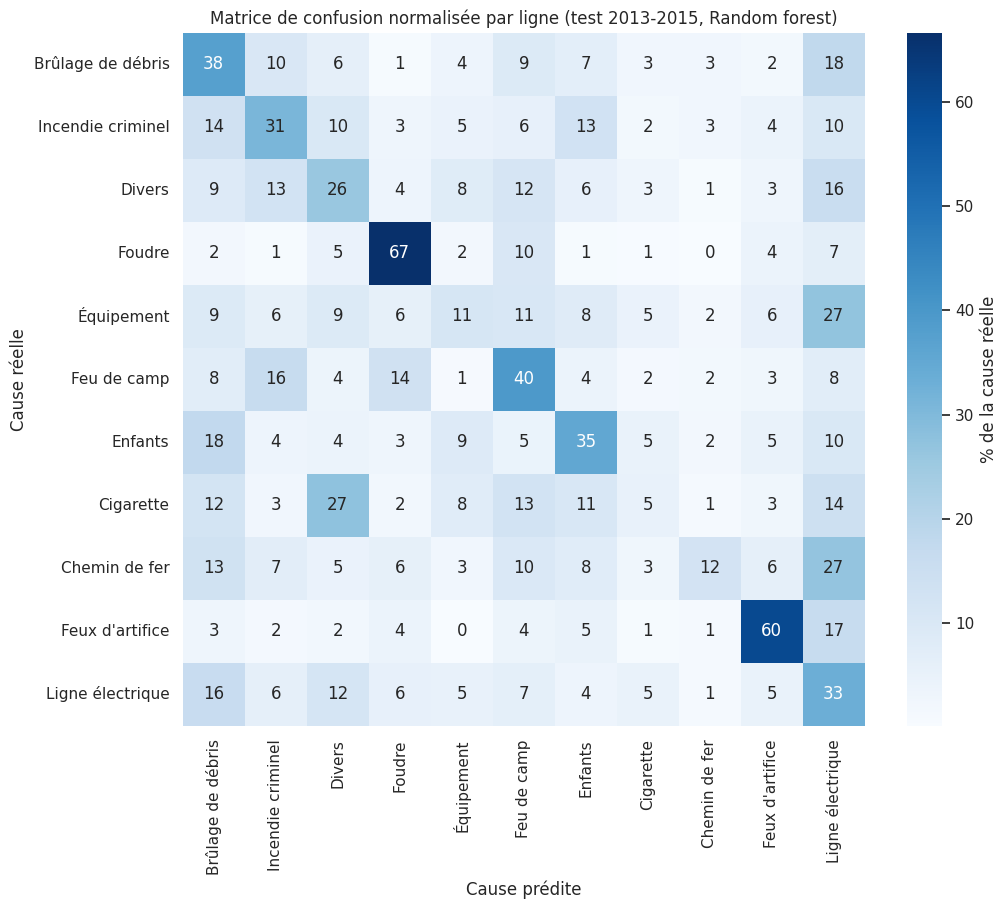

Confusions les plus fréquentes (% de la cause réelle) :
Cigarette          Divers               27.5
Équipement         Ligne électrique     27.0
Chemin de fer      Ligne électrique     26.7
Brûlage de débris  Ligne électrique     18.0
Enfants            Brûlage de débris    17.7
Feux d'artifice    Ligne électrique     16.5
Feu de camp        Incendie criminel    16.4
Ligne électrique   Brûlage de débris    16.2


In [35]:
mc = prep.matrice_confusion(pred_test).reindex(index=range(K), columns=range(K), fill_value=0)
mc_norm = mc.div(mc.sum(axis=1), axis=0) * 100
mc_norm.index = mc_norm.columns = CLASSES
fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(mc_norm, annot=True, fmt=".0f", cmap="Blues", ax=ax, cbar_kws={"label": "% de la cause réelle"})
ax.set_xlabel("Cause prédite"); ax.set_ylabel("Cause réelle")
ax.set_title(f"Matrice de confusion normalisée par ligne (test 2013-2015, {TYPE_FINAL})")
plt.show()
conf = mc_norm.where(~np.eye(K, dtype=bool)).stack().sort_values(ascending=False).head(8).round(1)
print("Confusions les plus fréquentes (% de la cause réelle) :"); print(conf.to_string())

**Confusions les plus fréquentes (en % de la cause réelle), plausibles.**
- **Cigarette → Divers (27,5 %)** : mêmes contextes (bords de routes, zones fréquentées), et « Divers » est la catégorie fourre-tout.
- **Équipement, chemin de fer, brûlage de débris → Ligne électrique (27,0 %, 26,7 %, 18,0 %)** : la ligne électrique a un **poids de plus de 20**, si bien que le modèle la prédit beaucoup trop souvent (15,2 % des prédictions du test, pour 1,9 % de feux réels, voir 8.4). Ses précisions très basses (0,042) en sont la conséquence. Il faudrait des poids moins extrêmes (par exemple la racine carrée de l'inverse de la fréquence).
- **Enfants → Brûlage de débris (17,7 %)** : feux résidentiels, au printemps, en après-midi.
- **Feu de camp → Incendie criminel (16,4 %)** : week-end, terrains publics, soirée.

### 8.3 Importance des variables

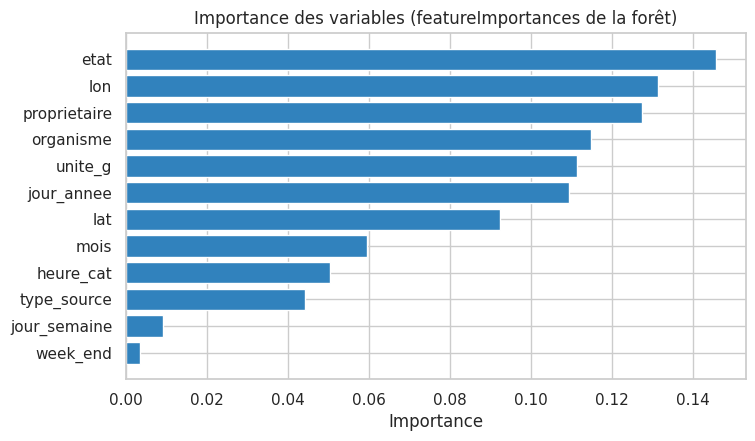

,etat,lon,proprietaire,organisme,unite_g,jour_annee,lat,mois,heure_cat,type_source,jour_semaine,week_end
part_%,14.6,13.1,12.8,11.5,11.1,10.9,9.2,6.0,5.0,4.4,0.9,0.4


In [36]:
if TYPE_FINAL == "Random forest":
    noms_rf = NUM + CAT_RF
    imp = pd.Series(modele_final.featureImportances.toArray(), index=noms_rf).sort_values()
    titre = "Importance des variables (featureImportances de la forêt)"
else:   # régression logistique : norme des coefficients, regroupée par variable d'origine
    meta = pre_final.transform(indexeur_cause.transform(test.limit(1))).schema["f_lr_brut"].metadata["ml_attr"]["attrs"]
    noms_cols = [a["name"] for a in sorted([a for t in meta.values() for a in t], key=lambda a: a["idx"])]
    coefs = np.abs(modele_final.coefficientMatrix.toArray()).sum(axis=0)
    origine = lambda nom: next(c for c in sorted(set(NUM + CAT_LR), key=len, reverse=True)
                               if nom.startswith(c + "_imp") or nom.startswith(c + "_oh"))
    imp = pd.Series(coefs, index=[origine(x) for x in noms_cols]).groupby(level=0).sum().sort_values()
    titre = "Importance (somme des |coefficients| par variable d'origine)"
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(imp.index, imp.values, color="#3182bd"); ax.set_title(titre); ax.set_xlabel("Importance")
plt.show()
(imp.sort_values(ascending=False) / imp.sum() * 100).round(1).rename("part_%").to_frame().T

**Importance des variables** (importance par impureté de la forêt, en % du total).
- **Géographie** : État 14,6 %, longitude 13,1 %, latitude 9,2 %, soit **36,9 %** au total.
- **Qui déclare et sur quel terrain** : propriétaire 12,8 %, organisme 11,5 %, unité 11,1 %, type de source 4,4 %, soit **39,8 %**. Le risque de **raccourci par le système de déclaration** est donc bien réel : le modèle apprend en partie les habitudes de classement des organismes, et pas seulement les causes.
- **Saison** : jour de l'année 10,9 % et mois 6,0 %. **Heure** : 5,0 %.
- Le jour de la semaine (0,9 %) et le week-end (0,4 %) comptent peu : leur effet est faible et déjà en partie capté ailleurs.

L'importance par impureté favorise les variables à nombreuses valeurs (coordonnées, unités) : ces chiffres sont à lire comme un ordre de grandeur.

### 8.4 Application aux feux de cause inconnue

In [37]:
etapes_deploiement = pre_final.stages + [modele_final,
                                         IndexToString(inputCol="prediction", outputCol="cause_predite", labels=CLASSES)]
modele_deploye = PipelineModel(stages=etapes_deploiement)

pred_inc = modele_deploye.transform(inconnu).groupBy("cause_predite").count().toPandas().set_index("cause_predite")["count"]
distrib = pd.DataFrame({
    "inconnues : cause prédite_%": pred_inc / pred_inc.sum() * 100,
    "connues 1992-2015_%": cibles.set_index("cause").loc[CLASSES, "part_connues_pct"],
    "test : prédite_%": pd.Series(np.asarray(mc.sum(axis=0)) / mc.values.sum() * 100, index=CLASSES),
    "test : réelle_%": pd.Series(m_final["support"] / m_final["support"].sum() * 100, index=CLASSES),
}).reindex(CLASSES).fillna(0).round(1)
print("Feux de cause inconnue :", int(pred_inc.sum()))
distrib

Feux de cause inconnue : 166723


,inconnues : cause prédite_%,connues 1992-2015_%,test : prédite_%,test : réelle_%
Brûlage de débris,14.6,25.0,16.9,28.5
Incendie criminel,25.6,16.4,11.2,10.4
Divers,8.0,19.1,12.1,25.5
Foudre,10.8,16.2,12.9,14.8
Équipement,6.1,8.6,5.3,7.4
Feu de camp,6.9,4.4,11.2,5.4
Enfants,8.2,3.6,6.9,2.2
Cigarette,8.4,3.1,2.7,2.3
Chemin de fer,4.6,2.0,1.7,0.7
Feux d'artifice,1.2,0.7,3.9,1.0


**Application aux 166 723 feux de cause inconnue.**

Par rapport aux causes connues, les prédictions donnent beaucoup plus d'**incendies criminels** (25,6 % contre 16,4 %), d'enfants (8,2 % contre 3,6 %) et de cigarettes (8,4 % contre 3,1 %). Elles donnent moins de brûlage de débris (14,6 % contre 25,0 %) et de « Divers » (8,0 % contre 19,1 %).

**À interpréter avec prudence :**
- Le modèle **surprédit les classes rares par construction**, à cause des poids. Sur le test, il prédit 15,2 % de lignes électriques pour 1,9 % réels, et 11,2 % de feux de camp pour 5,4 %. Les parts prédites ne sont donc **pas des estimations de proportions**.
- En revanche, la comparaison avec les **prédictions sur le test** est informative : le modèle y prédit 11,2 % d'incendies criminels, contre **25,6 %** sur les feux inconnus. Les feux de cause indéterminée ressemblent donc davantage à des contextes d'incendie criminel. C'est plausible, car une cause criminelle est difficile à établir, et l'enquête peut ne jamais conclure. Mais cela reste une **hypothèse**, pas une preuve.

In [38]:
# Où sont les feux de cause inconnue ? (organisme et État)
inc_org = (df_cause.groupBy("NWCG_REPORTING_AGENCY")
           .agg(F.count("*").alias("feux"), F.avg(F.col("cause").isNull().cast("int")).alias("part_inconnue"))
           .orderBy(F.desc("feux")).toPandas().round(3))
inc_etat = (df_cause.groupBy("STATE").agg(F.count("*").alias("feux"), F.avg(F.col("cause").isNull().cast("int")).alias("part_inconnue"))
            .orderBy(F.desc("part_inconnue")).limit(8).toPandas().round(3))
print(inc_org.to_string(index=False)); print(); print(inc_etat.to_string(index=False))

NWCG_REPORTING_AGENCY    feux  part_inconnue
               ST/C&L 1377090          0.099
                   FS  220497          0.000
                  BIA  119943          0.004
                  BLM   97034          0.059
                   IA   21841          0.999
                  NPS   20893          0.055
                  FWS   19331          0.046
                TRIBE    3739          0.003
                  DOD      81          0.901
                  BOR      14          0.214
                  DOE       2          1.000

STATE  feux  part_inconnue
   PR 22081          0.988
   HI  9895          0.982
   IA  4134          0.488
   ME 13150          0.455
   OK 43239          0.338
   SC 81315          0.275
   UT 30725          0.248
   KY 27089          0.207


**Les causes inconnues ne sont pas aléatoires.**
- **99,9 %** des feux déclarés par l'organisme `IA` (interagences, 21 841 feux) sont de cause inconnue, ainsi que 90,1 % de ceux du DOD (défense).
- **Porto Rico (98,8 %)** et **Hawaï (98,2 %)** n'ont presque aucune cause renseignée.
- À l'inverse, le Forest Service renseigne la cause de presque tous ses feux (0,0 % d'inconnues).

Pour ces contextes, le modèle **extrapole** à partir de cas presque absents de l'entraînement : ses prédictions y sont les moins fiables.

### 8.5 Limites

- **Qualité inégale des déclarations** : catégories utilisées différemment selon les organismes (New York : 61,5 % de « Divers »), heure manquante pour 47 % des feux.
- **Causes indéterminées non aléatoires** : concentrées dans certains organismes et territoires. Le modèle n'a jamais vu de cause connue pour certains d'entre eux.
- **Raccourci par le système de déclaration** : environ 40 % de l'importance vient de « qui déclare ». Le modèle prédit en partie la *manière de classer* d'un organisme.
- **Dérive temporelle** : les catégories évoluent (« Divers » de 17 % à 26 %). Le modèle devra être réentraîné régulièrement.
- **Poids de classes trop forts pour les causes très rares** : la ligne électrique est surprédite.
- **Corrélation, pas causalité** : un feu en Géorgie au printemps n'est pas *causé* par le printemps. Le modèle indique les **pistes les plus probables** pour orienter l'enquête, pas une conclusion.
- **Édition 2017 (1992-2015)** : les résultats sont à confirmer sur la 6e édition (1992-2020).

## 9. Passage à l'échelle : scikit-learn contre Spark

Même type de modèle (random forest, 30 arbres, profondeur 12, sous-échantillonnage 50 %, poids de classes identiques), mêmes variables et **même jeu de validation**, sur des fractions croissantes de l'entraînement.
- **Spark** : `RandomForestClassifier` sur les vecteurs en cache. La mémoire mesurée est la RSS maximale de la JVM, échantillonnée pendant l'entraînement ; elle inclut le cache des données.
- **scikit-learn** : `RandomForestClassifier(n_jobs=-1)` sur des tableaux NumPy. Les variables catégorielles y sont des index ordinaux (Spark, lui, les traite comme catégorielles). La mémoire est la RSS maximale du processus Python.

Pour scikit-learn, les variables de l'entraînement et de la validation sont exportées une fois en Parquet (`results/`) puis lues par pandas. C'est un chargement volontaire de toutes les données en mémoire, qui est précisément ce que l'on mesure.

In [39]:
import threading

from pyspark.ml.functions import vector_to_array
from sklearn.ensemble import RandomForestClassifier as SkRF
from sklearn.metrics import f1_score


class MemoireMax:
    """Échantillonne la RSS d'un processus (toutes les 0,2 s) pendant un bloc `with`."""
    def __init__(self, pid):
        self.proc, self.max, self._stop = psutil.Process(pid), 0, threading.Event()
    def _boucle(self):
        while not self._stop.is_set():
            self.max = max(self.max, self.proc.memory_info().rss); time.sleep(0.2)
    def __enter__(self):
        self._t = threading.Thread(target=self._boucle, daemon=True); self._t.start(); return self
    def __exit__(self, *a):
        self._stop.set(); self._t.join()


PID_JVM = spark.sparkContext._jvm.java.lang.ProcessHandle.current().pid()
FRACTIONS = [0.01, 0.05, 0.2, 0.5, 1.0]
P_ECHELLE = {"numTrees": 30, "maxDepth": 12}

# Export des vecteurs RF (entraînement, validation) pour scikit-learn
noms_x = [f"x{i}" for i in range(len(NUM) + len(CAT_RF))]
for nom, d in [("train", train_v), ("val", val_v)]:
    chemin = RACINE / "results" / f"echelle_{nom}.parquet"   # toujours régénéré : dépend du pipeline ajusté
    (d.withColumn("x", vector_to_array("f_rf")).select("label", "poids", *[F.col("x")[i].alias(c) for i, c in enumerate(noms_x)])
     .write.mode("overwrite").parquet(str(chemin)))
X_tr = pd.read_parquet(RACINE / "results" / "echelle_train.parquet")
X_va = pd.read_parquet(RACINE / "results" / "echelle_val.parquet")
print("Données scikit-learn :", X_tr.shape, X_va.shape, f"| {X_tr.memory_usage().sum() / 1e6:.0f} Mo en mémoire")

Données scikit-learn : (1302822, 14) (218114, 14) | 146 Mo en mémoire


Les données exportées pour scikit-learn occupent **146 Mo** en mémoire (1 302 822 × 14 colonnes) : c'est petit au regard des 8 Go de la machine.

In [40]:
echelle = []
for f in FRACTIONS:
    # --- Spark
    d = train_v if f == 1.0 else train_v.sample(fraction=f, seed=SEED).cache()
    n_f = d.count()
    with MemoireMax(PID_JVM) as mem:
        t0 = time.time(); m = creer_modele("Random forest", P_ECHELLE).fit(d); t_spark = time.time() - t0
    f1_spark = prep.metriques(prep.matrice_confusion(m.transform(val_v)), K)["f1_macro"]
    if f < 1.0:
        d.unpersist()
    del m; liberer_memoire()
    echelle.append({"fraction": f, "lignes": n_f, "outil": "Spark", "durée_s": t_spark,
                    "mémoire_max_Go": mem.max / 1e9, "F1 macro (val)": f1_spark})
    # --- scikit-learn
    s = X_tr.sample(frac=f, random_state=SEED) if f < 1.0 else X_tr
    sk = SkRF(n_estimators=30, max_depth=12, max_samples=0.5, max_features="sqrt", n_jobs=-1, random_state=SEED)
    with MemoireMax(os.getpid()) as mem:
        t0 = time.time(); sk.fit(s[noms_x].to_numpy(), s["label"].to_numpy(), sample_weight=s["poids"].to_numpy())
        t_sk = time.time() - t0
    f1_sk = f1_score(X_va["label"], sk.predict(X_va[noms_x].to_numpy()), average="macro", labels=list(range(K)), zero_division=0)
    echelle.append({"fraction": f, "lignes": len(s), "outil": "scikit-learn", "durée_s": t_sk,
                    "mémoire_max_Go": mem.max / 1e9, "F1 macro (val)": f1_sk})
    print(f"{f:>5.0%} | {n_f:>9} lignes | Spark {t_spark:6.1f} s F1 {f1_spark:.4f} | scikit-learn {t_sk:6.1f} s F1 {f1_sk:.4f}")
    del sk; liberer_memoire()
echelle = pd.DataFrame(echelle)
echelle.to_csv(RACINE / "results" / "passage_echelle.csv", index=False)
echelle.round(3)

   1% |     13099 lignes | Spark   41.7 s F1 0.2526 | scikit-learn    0.5 s F1 0.2523


   5% |     65002 lignes | Spark   68.5 s F1 0.2726 | scikit-learn    0.9 s F1 0.2700


  20% |    260719 lignes | Spark  119.7 s F1 0.2577 | scikit-learn    3.9 s F1 0.2617


  50% |    652550 lignes | Spark  180.7 s F1 0.2583 | scikit-learn   12.9 s F1 0.2589


 100% |   1302822 lignes | Spark  250.9 s F1 0.2510 | scikit-learn   12.1 s F1 0.2511


,fraction,lignes,outil,durée_s,mémoire_max_Go,F1 macro (val)
0,0.01,13099,Spark,41.695,6.219,0.253
1,0.01,13028,scikit-learn,0.473,0.617,0.252
2,0.05,65002,Spark,68.480,6.216,0.273
3,0.05,65141,scikit-learn,0.890,0.933,0.270
4,0.20,260719,Spark,119.674,6.214,0.258
5,0.20,260564,scikit-learn,3.900,1.090,0.262
6,0.50,652550,Spark,180.677,6.194,0.258
7,0.50,651411,scikit-learn,12.868,1.599,0.259
8,1.00,1302822,Spark,250.894,6.107,0.251
9,1.00,1302822,scikit-learn,12.135,1.819,0.251


**Résultats du passage à l'échelle (mêmes données, même modèle, même validation).**

| Lignes | Spark | scikit-learn | Rapport des temps |
|---|---|---|---|
| 13 099 (1 %) | 41,7 s | 0,5 s | environ 90 |
| 65 002 (5 %) | 68,5 s | 0,9 s | environ 75 |
| 260 719 (20 %) | 119,7 s | 3,9 s | environ 30 |
| 652 550 (50 %) | 180,7 s | 12,9 s | environ 14 |
| 1 302 822 (100 %) | 250,9 s | 12,1 s | environ 21 |

- **Spark n'est jamais plus rapide sur cette machine**, même à 100 %. L'écart se réduit quand le volume augmente (de 90 à environ 20 fois), car le coût fixe de Spark (planification des tâches, sérialisation, JVM) s'amortit. Mais les données tiennent largement en mémoire. Le temps de scikit-learn à 100 % (12,1 s) est un peu inférieur à celui à 50 % (12,9 s) : c'est du bruit de mesure, avec 12 threads partagés.
- **Mémoire** : la JVM reste vers **6,1-6,2 Go quelle que soit la fraction**. C'est une empreinte fixe qui inclut le tas de 4 Go, les données en cache et le hors-tas. Le processus Python de scikit-learn passe de 0,6 à **1,8 Go**.
- **Performance** : le F1 macro reste entre **0,25 et 0,27 quelle que soit la taille**. Le meilleur score est même obtenu avec 5 % des données (0,273 pour Spark), et 100 % donne 0,251. **Plus de données n'améliore pas ce modèle** : sa capacité est bornée (profondeur 12), et la limite vient des variables disponibles et de la dérive temporelle, pas du nombre d'exemples. Les deux bibliothèques obtiennent des scores quasi identiques, ce qui valide la comparaison.

**Conclusion.** Sur une seule machine avec ~1,3 M lignes et 146 Mo de variables, **scikit-learn est 20 fois plus rapide** pour entraîner. Spark devient intéressant quand les données **ne tiennent plus en mémoire d'une machine** (des dizaines de Go et plus), quand on dispose d'un **cluster**, ou pour les étapes en amont. Ici, Spark a permis d'ingérer, de nettoyer et d'agréger 1,9 M lignes × 38 colonnes sans jamais les charger dans pandas.

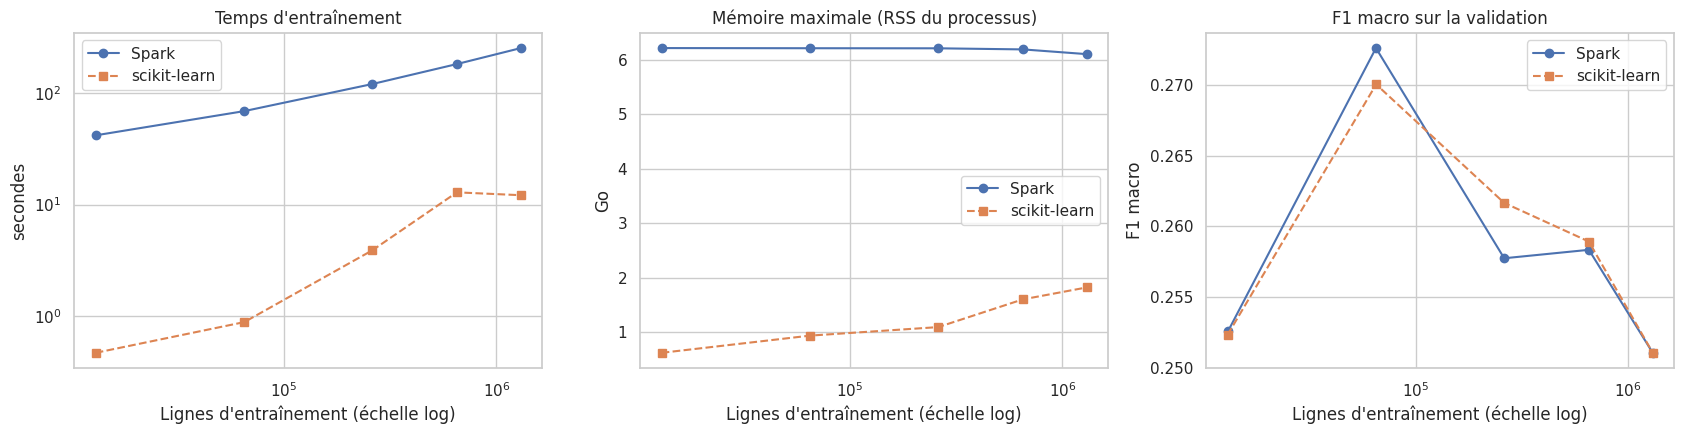

In [41]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for outil, st in [("Spark", "o-"), ("scikit-learn", "s--")]:
    d = echelle[echelle["outil"] == outil]
    axes[0].plot(d["lignes"], d["durée_s"], st, label=outil)
    axes[1].plot(d["lignes"], d["mémoire_max_Go"], st, label=outil)
    axes[2].plot(d["lignes"], d["F1 macro (val)"], st, label=outil)
for ax, t, yl in zip(axes, ["Temps d'entraînement", "Mémoire maximale (RSS du processus)", "F1 macro sur la validation"],
                     ["secondes", "Go", "F1 macro"]):
    ax.set_xscale("log"); ax.set_xlabel("Lignes d'entraînement (échelle log)"); ax.set_title(t); ax.set_ylabel(yl); ax.legend()
axes[0].set_yscale("log")
plt.tight_layout(); plt.show()
del X_tr, X_va

## 10. Préparation du déploiement

In [42]:
CHEMIN_MODELE = RACINE / "models" / "pipeline_cause_feux"
t0 = time.time()
modele_deploye.write().overwrite().save(str(CHEMIN_MODELE))
taille_modele = sum(f.stat().st_size for f in CHEMIN_MODELE.rglob("*") if f.is_file())
print(f"PipelineModel sauvegardé dans {CHEMIN_MODELE.relative_to(RACINE)} ({taille_modele / 1e6:.1f} Mo, {time.time() - t0:.0f} s)")
print("Étapes :", [type(s).__name__ for s in modele_deploye.stages])

PipelineModel sauvegardé dans models/pipeline_cause_feux (6.7 Mo, 9 s)
Étapes : ['SQLTransformer', 'SQLTransformer', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'StringIndexerModel', 'ImputerModel', 'OneHotEncoderModel', 'VectorAssembler', 'VectorAssembler', 'StandardScalerModel', 'RandomForestClassificationModel', 'IndexToString']


Le `PipelineModel` complet est sauvegardé (6,7 Mo, 9 s). Il contient les 2 `SQLTransformer` (préparation et regroupement), les `StringIndexer`, l'`Imputer`, les assembleurs, la forêt et l'`IndexToString` final. Il prend donc en entrée les **colonnes brutes** et renvoie directement le libellé de la cause.

In [43]:
frequentes_finales = {}
for c, s in SEUILS.items():
    frequentes_finales[c] = prep.modalites_frequentes(prep.preparer(train_val), c, s)
index_finaux = {s.getInputCol(): list(s.labels) for s in pre_final.stages
                if hasattr(s, "labels") and hasattr(s, "getInputCol")}
schema = {
    "description": "Entrées BRUTES attendues (format FPA FOD 4e édition). Le PipelineModel applique lui-même "
                   "la préparation (SQLTransformer) : aucun nettoyage préalable n'est nécessaire.",
    "modele": {"chemin": "models/pipeline_cause_feux", "type": TYPE_FINAL, "hyperparametres": PARAMS_FINAL,
               "periode_apprentissage": [1992, 2012], "metrique_test_f1_macro": round(m_final["f1_macro"], 4)},
    "classes_predites_dans_l_ordre": CLASSES,
    "sorties": {"cause_predite": "libellé de la cause", "probability": f"vecteur de {K} probabilités, dans l'ordre ci-dessus"},
    "entrees": {
        "DISCOVERY_DATE": {"type": "double", "format": "jour julien (ex. 2453403.5 = 2005-02-02)"},
        "DISCOVERY_TIME": {"type": "string", "format": "HHMM (ex. '1430')", "optionnel": True},
        "LATITUDE": {"type": "double", "bornes": [prep.LAT_MIN, prep.LAT_MAX]},
        "LONGITUDE": {"type": "double", "bornes": [prep.LON_MIN, prep.LON_MAX]},
        "STATE": {"type": "string", "valeurs": index_finaux["etat"]},
        "OWNER_DESCR": {"type": "string", "valeurs": index_finaux["proprietaire"]},
        "NWCG_REPORTING_AGENCY": {"type": "string", "valeurs": index_finaux["organisme"]},
        "SOURCE_SYSTEM_TYPE": {"type": "string", "valeurs": index_finaux["type_source"]},
        "NWCG_REPORTING_UNIT_ID": {"type": "string", "unites_reconnues": frequentes_finales["unite"],
                                   "autre_valeur": "regroupée en AUTRE"},
    },
    "versions": {"spark": spark.version, "java": java, "python": sys.version.split()[0]},
}
(RACINE / "models" / "schema_entree.json").write_text(json.dumps(schema, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps({k: schema[k] for k in ["modele", "classes_predites_dans_l_ordre", "versions"]}, indent=2, ensure_ascii=False))

{
  "modele": {
    "chemin": "models/pipeline_cause_feux",
    "type": "Random forest",
    "hyperparametres": {
      "numTrees": 30,
      "maxDepth": 12
    },
    "periode_apprentissage": [
      1992,
      2012
    ],
    "metrique_test_f1_macro": 0.2568
  },
  "classes_predites_dans_l_ordre": [
    "Brûlage de débris",
    "Incendie criminel",
    "Divers",
    "Foudre",
    "Équipement",
    "Feu de camp",
    "Enfants",
    "Cigarette",
    "Chemin de fer",
    "Feux d'artifice",
    "Ligne électrique"
  ],
  "versions": {
    "spark": "3.5.9",
    "java": "openjdk version \"11.0.32.1\" 2026-08-18",
    "python": "3.10.12"
  }
}


In [44]:
# Rechargement depuis le disque et prédiction sur deux feux fictifs saisis à la main
modele_charge = PipelineModel.load(str(CHEMIN_MODELE))
feux_fictifs = spark.createDataFrame([
    Row(DISCOVERY_DATE=jour_julien("2016-07-04"), DISCOVERY_TIME="2215", LATITUDE=33.75, LONGITUDE=-84.39, STATE="GA",
        OWNER_DESCR="PRIVATE", NWCG_REPORTING_AGENCY="ST/C&L", SOURCE_SYSTEM_TYPE="NONFED", NWCG_REPORTING_UNIT_ID="USGAGAS"),
    Row(DISCOVERY_DATE=jour_julien("2016-08-10"), DISCOVERY_TIME="1645", LATITUDE=46.9, LONGITUDE=-114.2, STATE="MT",
        OWNER_DESCR="USFS", NWCG_REPORTING_AGENCY="FS", SOURCE_SYSTEM_TYPE="FED", NWCG_REPORTING_UNIT_ID="USMTLNF"),
])
sortie = (modele_charge.transform(feux_fictifs)
          .withColumn("p", vector_to_array("probability"))
          .select("STATE", "DISCOVERY_TIME", "proprietaire", "unite_g", "cause_predite", "p").toPandas())
for _, ligne in sortie.iterrows():
    top3 = sorted(zip(CLASSES, ligne["p"]), key=lambda x: -x[1])[:3]
    print(f"{ligne['STATE']} {ligne['DISCOVERY_TIME']} ({ligne['proprietaire']}, unité {ligne['unite_g']}) -> "
          f"{ligne['cause_predite']} | top 3 : " + ", ".join(f"{c} {p:.0%}" for c, p in top3))

GA 2215 (PRIVATE, unité USGAGAS) -> Brûlage de débris | top 3 : Brûlage de débris 22%, Enfants 20%, Incendie criminel 14%
MT 1645 (USFS, unité USMTLNF) -> Foudre | top 3 : Foudre 63%, Feu de camp 24%, Cigarette 5%


**Prédiction d'exemple après rechargement.**
- **Géorgie, 4 juillet à 22 h 15, terrain privé** : prédiction « brûlage de débris » à **22 %**, devant enfants (20 %) et incendie criminel (14 %). Le modèle est **peu sûr de lui**, et les feux d'artifice n'apparaissent pas dans le top 3, malgré la date. En Géorgie, sur terrain privé, le brûlage de débris domine fortement. La bonne présentation pour un enquêteur est donc une **liste ordonnée de pistes avec leurs probabilités**, pas une réponse unique.
- **Montana, 10 août à 16 h 45, Forest Service** : **foudre à 63 %**, cohérent avec l'EDA (été, Ouest, terres fédérales, orage d'après-midi).

Les messages `WARNING: An illegal reflective access` viennent de Java 11 : Spark estime la taille des objets en mémoire par réflexion. Ce message, propre aux JVM postérieures à Java 8, est sans conséquence sur les résultats.

**Servir ce modèle.** Un modèle Spark ML exige une **JVM et une SparkSession** pour prédire, même pour un seul feu. Plusieurs options :
1. **Spark local derrière une petite API** (FastAPI, par exemple). La session est démarrée une fois (environ 10 s), puis chaque requête crée un petit DataFrame et appelle `transform`. C'est simple, mais il faut environ 2 Go de mémoire et compter quelques centaines de millisecondes par requête.
2. **Prédiction par lots** : un job Spark quotidien applique le modèle aux nouveaux feux de la base. C'est l'usage naturel de Spark, et il suffit pour orienter les enquêtes, qui ne demandent pas une réponse à la seconde.
3. **Export vers un autre format** : les outils pour Spark ML (MLeap, ONNX) sont partiels ou peu maintenus. Vu la section 9, l'option la plus simple serait de **réentraîner l'équivalent scikit-learn** (même score, 20 fois plus rapide, aucune JVM), à condition de réécrire la préparation en pandas.

In [45]:
# Libération du cache et arrêt de la session Spark
for d in (train_v, val_v, tv_v, pred_test):
    d.unpersist()
duree_totale = time.time() - DEBUT_NOTEBOOK
spark.stop()
print(f"SparkSession arrêtée. Durée totale d'exécution du notebook : {duree_totale / 60:.1f} min")

SparkSession arrêtée. Durée totale d'exécution du notebook : 62.7 min


**Durée totale d'exécution : 62,7 minutes** (de « Restart Kernel » à l'arrêt de Spark).

| Étape lourde | Durée mesurée |
|---|---|
| Conversion SQLite → Parquet (une fois) | 25 s |
| Passe unique sur les manques et cardinalités | 32 s |
| Préparation et mise en cache des vecteurs | 144 s |
| Grille (3 régressions logistiques, 3 forêts) | 1 382 s (environ 23 min) |
| Forêt avec la taille (fuite) | 315 s |
| Modèle final (1,52 M feux) | 598 s |
| Passage à l'échelle (Spark) | 662 s (environ 11 min) |

## 11. Conclusion

**Réponse au problème.** Avec les seules informations de découverte, la cause d'un feu se prédit **nettement mieux que par des règles simples**, mais reste difficile.
- Sur le test 2013-2015, la forêt atteint un **F1 macro de 0,257**, contre 0,156 pour « la cause dominante de l'État » et 0,040 pour la classe majoritaire.
- La **foudre** est bien reconnue (F1 0,713).
- Les causes humaines « techniques » (cigarette, chemin de fer, ligne électrique, équipement) restent quasi indistinguables.
- Pour les enquêteurs, le bon usage est une **liste ordonnée de pistes**, pas une réponse unique.

**Résultats clés.**
- Ingestion : Parquet **8,8 fois plus petit** que le SQLite ; lecture d'une colonne 5 fois plus rapide que de toutes.
- Fuites : la taille finale n'apporte que +0,006 de F1 macro, mais elle est exclue car inconnue à la découverte ; le nom du feu contient la cause dans 1,18 % des cas (91 % de justesse pour « LIGHTNING »).
- Variables : géographie (37 %) et système de déclaration (40 %) dominent, devant la saison (17 %).
- Feux de cause inconnue : ils ressemblent davantage à des incendies criminels (25,6 % des prédictions, contre 11,2 % sur le test). C'est une hypothèse, pas une preuve.

**Comparaison avec l'étape 1.**

| | Étape 1 (requins) | Étape 2 (feux) |
|---|---|---|
| Volume | 4 087 lignes | 1,71 M lignes de cause connue |
| Outils | pandas, scikit-learn | Spark SQL, `pyspark.ml` |
| Découpage | aléatoire stratifié (+ contrôle temporel) | **temporel** |
| Préparation | fonctions Python | **expressions SQL** dans le `PipelineModel` |
| Principale difficulté | peu de données, biais de recensement | **mémoire** (4 Go), dérive, déclarations hétérogènes |

Les leçons sont communes : les fuites, les biais de déclaration et la séparation corrélation/causalité comptent plus que le choix de l'algorithme.

**Le volume justifie-t-il Spark ici ?** Pour l'**entraînement, non** : scikit-learn est 20 fois plus rapide sur cette machine, et le score ne progresse pas avec le volume. Spark est utile pour l'**ingestion et la préparation** sans charger les données en mémoire, et deviendrait indispensable au-delà de la mémoire d'une machine ou sur un cluster.

**Perspectives.**
- Ajouter des variables de contexte connues à la découverte : distance aux routes, voies ferrées et lignes électriques, météo (orages), densité de population. Ce sont elles qui manquent pour les causes « techniques ».
- Atténuer les poids de classes, ou ajuster des seuils par classe.
- Refaire l'étude sur la **6e édition (1992-2020)**.
- Déploiement par lots sur Spark, ou réentraînement équivalent en scikit-learn pour un service temps réel.